# Fixing the run's record, number by number

**A runnable demo of `eval.py`, the iteration-7 Step 0 evaluation of the run "prompt bans substitute, not just subtract".**

The run asks whether a prompt instruction or ban changes *which* algorithm an open-weight LLM writes, and where inside the model that choice is held. For example, banning Dijkstra may make Qwen3-8B write Bellman-Ford. By iteration 6 the run's report quoted hundreds of numbers from many experiments, and this evaluation repairs that record before the paper quotes it. It works in five steps:

1. It re-derives every number it touches from the **raw rows** of the iteration-6 experiments.
2. It corrects the report in place, as verbatim `old_text -> new_text` pairs marked `(iteration-7 correction)`.
3. It proves that every pair applies exactly once to a copy of the report, with no overlaps (the **apply test**).
4. It lints the corrected report for leftover wrong claims (the **residual-claim lint**).
5. It ledgers every value as `MATCH`, `NEW`, `CARRIED` or `CORRECTED` against what the record printed.

No model is run: the evaluation is CPU-only, and this notebook finishes in well under a minute.

**The full run** has twelve items (0a to 0l) over 69 vendored inputs (about 96 MB), plus paid blind judges and a dated web pass. It ends with:
- 54 corrections (apply test 54/54);
- 603 MATCH, 117 NEW, 1 CARRIED and 3 CORRECTED values;
- lint flags going from 16 to 0.

**This demo** runs the three items that read one experiment, the exchange and site experiment `art_rMlbrjVB1c__` (Qwen3-8B, Stage A). It runs them with the whole correction machinery, on the bundled `mini_demo_data.json`, and with the original code:

| Item | What it repairs | Headline the demo reproduces |
|-|-|-|
| **0a** | The Stage A tables print commit0's *attempted* share (invalid rows count as not-Y; validity gate: pass ratio at least 0.8), not "the share of correct programs". A correct-Y column is added. | Shortest path, exchange at blocks 0-35: 24/30 attempts, 21/30 correct programs. Grid: 14/30 attempts, 3/30 correct (fails the gate). 5 cells fail the gate. Post-hoc correct-Y McNemar: 21:0, 15:2, 11:0 |
| **0b** | The site of the choice is stated as open. | Condition-span beta -1.70 [-3.96, 0.42] (kth smallest) and -0.56 [-4.93, 2.91] (connected components); NEW Table 254b of noise sites against the exchange |
| **0f** | A dose caveat is added for the top-five push. | 1 to 8 ban units overshoot the forced-prompt manifold: the centroids span PC1 -0.098 to +0.144, while the alpha-1 points move from +0.09 to -0.44 |

The results section checks every output against the published outputs of the full run. It then plots the Stage A cells and the top-five push in activation space.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (eval.py and src/common.py log through it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only, at Colab's versions
# (the artifact pins numpy 2.5.4 and scipy 1.18.1; every call it makes exists in these versions too)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
# ---- eval.py's import block, as in the script ----
from __future__ import annotations

import argparse
import csv
import json
import resource
import subprocess
import sys
import time
from pathlib import Path

# WS = Path(__file__).resolve().parent     # notebook: no __file__; WS is set in the src/common.py cell below
# sys.path.insert(0, str(WS / "src"))      # notebook: the src/ modules are cells of this notebook, not imports

from loguru import logger  # noqa: E402

# from common import (AUDIT, INPUTS, MARK, READ_DATE, TABLES, inp, read_json, setup_logging, sha256_file,  # noqa: E402
#                     write_json)
# from corrections import V, Registry, apply_all, lint, unified_diff  # noqa: E402
# from editor import Editor  # noqa: E402
# notebook: these names are defined by the src/common.py, src/corrections.py and src/editor.py cells below

# ---- notebook additions: data loading, a namespace for `Q.item_0a(...)`, plotting ----
import http.client
import urllib.request
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-7/evaluation-6/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["description"])
print(f"dataset {data['dataset']!r}: {len(data['examples'])} Stage A cells with "
      f"{sum(e['n_rows'] for e in data['examples'])} raw labelled rows "
      f"(of {data['source']['labels_jsonl']['rows_total']} rows in the experiment's data/labels.jsonl)")
print(f"{len(data['files'])} result files; report: {len(data['report']['lines'])} of {data['report']['n_lines']} lines "
      f"({data['report']['kept']})")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Bundled input of code_demo.ipynb: the Stage A cells of the exchange and site experiment (art_rMlbrjVB1c__, Qwen3-8B) with their raw labelled rows, the result files that items 0a, 0b and 0f of eval.py read, the report window they correct, and the published outputs.
dataset 'stage_a_cells': 75 Stage A cells with 2190 raw labelled rows (of 4320 rows in the experiment's data/labels.jsonl)
4 result files; report: 814 of 6345 lines (lines 5497 to 6212 and every heading line; the other lines are empty)


## Configuration

This evaluation has no training loop and no sample count. Its only scale is **how many of its items run**. Each item re-derives one part of the record from raw rows and registers its corrections with the shared editor.

- `ITEMS`: the items to run.
  - The minimum is `["0a"]`, since 0b reuses 0a's cells.
  - This demo bundles the inputs of 0a, 0b and 0f, so `["0a", "0b", "0f"]` is the largest scale it can reach.
  - The original `eval.py` always runs all twelve items, 0a to 0l. That needs the 69 inputs vendored in the artifact's `inputs/` folder.
- `RLIMIT_AS_GB`: the address-space cap that `eval.py`'s `set_limits()` puts on the process. The original is 24 GB. The cap stays on the notebook's kernel until the kernel restarts.
- `WORKDIR`: stands in for the artifact folder `WS`. The bundled inputs go under `inputs/`, and the outputs under `results/`, `tables/` and `logs/`, laid out as the script does.

The script's one CLI flag, `--stages {all, offline}`, only decides whether the 0i judges and the 0k web pass run again or are read from cache. Neither item is in this demo.

In [5]:
# ---- tunable parameters (scaled up from the minimum ["0a"] during testing) ----
ITEMS = ["0a", "0b", "0f"]      # minimum: ["0a"]; largest in this demo: ["0a", "0b", "0f"]
                                # original eval.py: all twelve items "0a" ... "0l" (needs the artifact's 69 vendored inputs)
RLIMIT_AS_GB = 24               # eval.py set_limits(): address-space cap of 24 GB (original value)
WORKDIR = "record_repair_demo"  # stands in for the artifact folder (WS), created next to the notebook

assert "0a" in ITEMS and set(ITEMS) <= {"0a", "0b", "0f"}, "this demo bundles the inputs of items 0a, 0b and 0f only"

## `src/common.py`: shared paths, IO, hashing and logging

Every path hangs off `WS`, the artifact folder, and inputs are read from the vendored copies under `inputs/<artifact_id>/`. Two lines change in the notebook:

- `WS` is the demo work folder, because a notebook has no `__file__`.
- `DEPS_ROOT` falls back to `WS`, because `WS.parents[2]` (the run server's invention-loop folder) does not exist under Colab's `/content`. `DEPS_ROOT` is only used to vendor inputs from sibling artifacts, a step this demo replaces with its bundled data.

In [6]:
"""Shared paths, IO, hashing and logging for the iteration-7 record repair (Step 0).

Every path is derived from this file's location (the workspace root) or from the AII_RUN_ROOT environment
variable, so no absolute server path is written into any published file. Inputs are read from the vendored
copies under inputs/<artifact_id>/ once src/stage_inputs.py has resolved and hashed them.
"""

from __future__ import annotations

import hashlib
import json
import os
import sys
from pathlib import Path
from typing import Any, Iterable

from loguru import logger

WS = Path(WORKDIR).resolve()  # notebook: was Path(__file__).resolve().parents[1], the artifact folder
# ONE anchor for every input another artifact produced. On the run server the artifacts sit under the invention-loop
# folder three levels above this workspace; in the published repository each artifact is a sibling folder of this one
# (looked up by its workspace folder name, then by its artifact id). Override with the environment variable
# AII_DEPS_ROOT. If no source is reachable, the sha256-verified copies vendored under inputs/ are used.
DEPS_ROOT = Path(os.environ.get("AII_DEPS_ROOT", str(WS)))  # notebook: was str(WS.parents[2]), absent under /content
DEP_REL = {  # artifact id -> folder under DEPS_ROOT on the run server
    "art_lpQalcAXMGr1": "iter_6/gen_art/gen_art_experiment_29",  # engine control
    "art_rMlbrjVB1c__": "iter_6/gen_art/gen_art_experiment_30",  # exchange and site experiment
    "art_zNyBP6zieI5u": "iter_6/gen_art/gen_art_experiment_31",  # Gemma
    "art_dbUtqBjT0tPf": "iter_6/gen_art/gen_art_experiment_32",  # NLA
    "art_aRTQM6CQ0Dre": "iter_6/gen_art/gen_art_evaluation_5",  # iteration-6 Step 0 (read by path)
    "art_OUuQUYQn5voE": "iter_6/gen_art/gen_art_research_3",  # iteration-6 positioning audit (read by path)
}
DEPENDENCIES = ("art_lpQalcAXMGr1", "art_rMlbrjVB1c__", "art_zNyBP6zieI5u", "art_dbUtqBjT0tPf")
REPORT_REL = "iter_7/gen_strat/current_report.md"  # the object being corrected, under DEPS_ROOT


def dep_dir(artifact: str) -> Path:
    """Server layout first, then a sibling folder named like the workspace folder, then one named by the id."""
    rel = DEP_REL[artifact]
    for cand in (DEPS_ROOT / rel, WS.parent / Path(rel).name, WS.parent / artifact):
        if cand.is_dir():
            return cand
    return DEPS_ROOT / rel


DEP_DIRS = {a: dep_dir(a) for a in DEPENDENCIES}
NONDEP_DIRS = {a: dep_dir(a) for a in DEP_REL if a not in DEPENDENCIES}
REPORT_SRC = DEPS_ROOT / REPORT_REL
SHORT = {"art_lpQalcAXMGr1": "engine", "art_rMlbrjVB1c__": "exchange", "art_zNyBP6zieI5u": "gemma",
         "art_dbUtqBjT0tPf": "nla", "art_aRTQM6CQ0Dre": "step0_iter6", "art_OUuQUYQn5voE": "positioning_iter6"}

INPUTS = WS / "inputs"
TABLES = WS / "tables"
AUDIT = WS / "audit"
LOGS = WS / "logs"
RESULTS = WS / "results"
READ_DATE = "2026-10-22"
MARK = "(iteration-7 correction)"


def setup_logging(name: str) -> None:
    LOGS.mkdir(parents=True, exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(LOGS / f"{name}.log", rotation="30 MB", level="DEBUG")


def inp(artifact: str, rel: str) -> Path:
    """Path of a vendored input file."""
    return INPUTS / artifact / rel


def src_ref(artifact: str, rel: str, key: str | None = None) -> str:
    return f"{artifact}:{rel}" + (f"#{key}" if key else "")


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any, indent: int = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(obj, indent=indent, default=_default, ensure_ascii=False) + "\n")


def _default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, set):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    return [json.loads(l) for l in Path(p).read_text().splitlines() if l.strip()]


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open("w") as f:
        for r in rows:
            f.write(json.dumps(r, default=_default, ensure_ascii=False) + "\n")


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def truthy(v: Any) -> bool:
    """Label rows store booleans as bools or as 'True'/'False' strings."""
    if isinstance(v, bool):
        return v
    if isinstance(v, str):
        return v.strip().lower() == "true"
    return bool(v)


def fmt(x: float | None, nd: int = 2) -> str:
    if x is None:
        return "n/a"
    return f"{x:.{nd}f}"


def fmt_p(p: float | None) -> str:
    """Report-style p value: 3 significant digits above 1e-3, scientific below."""
    if p is None:
        return "n/a"
    if p >= 0.001:
        return f"{p:.3f}" if p < 0.1 else f"{p:.2f}"
    return f"{p:.1e}"

## Bundled inputs, written where the original code reads them

The full run vendors its 69 inputs under `inputs/<artifact_id>/` and hashes them into `input_hashes.json` (`src/stage_inputs.py`). The demo replaces that step: it writes its bundled inputs to the same paths, so the item code below reads them unchanged.

- **The four result files** of the exchange and site experiment (`stage_a.json`, `commit0.json`, `site_grid.json`, `top5_push.json`) are written byte for byte. Their sha256 is checked against the hash the full run recorded.
- **The 2,190 Stage A rows** are written as `data/labels.jsonl`, one labelled program per row.
  - The rows are cut to the fields the code reads: task, arm, slot, crn key, label and passed.
  - The 2,130 rows of the noise-site (`ST_*`), `DMD_*` and top-five arms are left out; `stage_a_cells()` skips those arms anyway.
- **The report** is written with lines 5497 to 6212 (Section 6.4 to `# References`) and every heading, each at its original line number; every other line is empty. That window holds every line these three items edit and everything the lint scans, so line numbers, sections, the apply test and the lint behave as they do on the full report.

In [7]:
# notebook: stands in for `from stage_inputs import resolve_all; hashes = resolve_all()` in eval.py's main()
for rel, text in data["files"].items():
    p = INPUTS / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(text, encoding="utf-8")
    ok = sha256_file(p) == data["source"]["files"][rel]["recorded_sha256"]
    print(f"{rel:46} {p.stat().st_size:>7} bytes   sha256 equals input_hashes.json: {ok}")

stage_a_rows = [r for ex in data["examples"] for r in ex["rows"]]
write_jsonl(inp("art_rMlbrjVB1c__", "data/labels.jsonl"), stage_a_rows)
print(f"{'art_rMlbrjVB1c__/data/labels.jsonl':46} {len(stage_a_rows):>7} rows    (the Stage A arms)")

rp = data["report"]
report_path = INPUTS / "report" / "current_report.md"
report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text("\n".join(rp["lines"].get(str(i), "") for i in range(1, rp["n_lines"] + 1)), encoding="utf-8")
print(f"{'report/current_report.md':46} {len(rp['lines']):>7} lines   of {rp['n_lines']} (full report: "
      f"{rp['full_bytes']} bytes, sha256 {rp['full_sha256'][:16]}..., recorded {rp['recorded_sha256'][:16]}...)")

art_rMlbrjVB1c__/results/stage_a.json            46101 bytes   sha256 equals input_hashes.json: True
art_rMlbrjVB1c__/predictions/commit0.json        17175 bytes   sha256 equals input_hashes.json: True
art_rMlbrjVB1c__/results/site_grid.json          48457 bytes   sha256 equals input_hashes.json: True
art_rMlbrjVB1c__/results/top5_push.json           8685 bytes   sha256 equals input_hashes.json: True
art_rMlbrjVB1c__/data/labels.jsonl                2190 rows    (the Stage A arms)
report/current_report.md                           814 lines   of 6345 (full report: 1007979 bytes, sha256 f97c53f62fb222b4..., recorded f97c53f62fb222b4...)


## `src/stats.py`: exact small-sample statistics

Item 0a uses two of these statistics:
- the **Clopper-Pearson** interval, for every share;
- the **exact McNemar** test (a two-sided binomial test of `b` against `b + c`), for the post-hoc paired contrast.

The module also holds the sign test, the Durkalski cluster adjustment, Cohen's kappa and the cluster bootstrap, which items 0h and 0i use. It is copied unchanged.

In [8]:
"""Exact small-sample statistics used by the record repair (scipy where it is exact, closed forms otherwise)."""

from __future__ import annotations

import math
from typing import Sequence

import numpy as np
from scipy import stats as st


def clopper_pearson(k: int, n: int, alpha: float = 0.05) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    lo = 0.0 if k == 0 else float(st.beta.ppf(alpha / 2, k, n - k + 1))
    hi = 1.0 if k == n else float(st.beta.ppf(1 - alpha / 2, k + 1, n - k))
    return (lo, hi)


def binom_two_sided(k: int, n: int, p0: float = 0.5) -> float:
    """Exact two-sided binomial test (minimum-likelihood method, as scipy.stats.binomtest)."""
    if n == 0:
        return 1.0
    return float(st.binomtest(k, n, p0, alternative="two-sided").pvalue)


def mcnemar_exact(b: int, c: int) -> float:
    """Exact McNemar: two-sided binomial test of b against b + c at 0.5."""
    return binom_two_sided(b, b + c, 0.5) if b + c else 1.0


def mcnemar_from_pairs(xs: Sequence[int], ys: Sequence[int]) -> dict:
    b = sum(1 for x, y in zip(xs, ys) if x == 1 and y == 0)
    c = sum(1 for x, y in zip(xs, ys) if x == 0 and y == 1)
    n = len(xs)
    return {"n": n, "b": b, "c": c, "p": mcnemar_exact(b, c),
            "effect": (sum(xs) - sum(ys)) / n if n else None}


def sign_test(diffs: Sequence[float]) -> dict:
    pos = sum(1 for d in diffs if d > 0)
    neg = sum(1 for d in diffs if d < 0)
    return {"n_pos": pos, "n_neg": neg, "n_zero": sum(1 for d in diffs if d == 0),
            "p": binom_two_sided(pos, pos + neg) if pos + neg else 1.0}


def sign_test_floor(n_clusters: int) -> float:
    """Smallest attainable two-sided p of an exact sign test over n clusters (all n in one direction)."""
    return min(1.0, 2.0 * 0.5 ** n_clusters)


def durkalski_mcnemar(clusters: dict[str, tuple[int, int]]) -> dict:
    """Durkalski et al. (2003) cluster-adjusted McNemar statistic.

    clusters maps a cluster id to (b_k, c_k), its counts of (x=1, y=0) and (x=0, y=1) pairs. The statistic is
    (B - C)^2 / sum_k (b_k - c_k)^2, referred to chi-square with 1 df (asymptotic; reported as a sensitivity).
    """
    B = sum(b for b, _ in clusters.values())
    C = sum(c for _, c in clusters.values())
    den = sum((b - c) ** 2 for b, c in clusters.values())
    if den == 0:
        return {"B": B, "C": C, "chi2": None, "p": None, "n_clusters": len(clusters)}
    chi2 = (B - C) ** 2 / den
    return {"B": B, "C": C, "chi2": chi2, "p": float(st.chi2.sf(chi2, 1)), "n_clusters": len(clusters)}


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    ph = k / n
    den = 1 + z * z / n
    c = (ph + z * z / (2 * n)) / den
    h = z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / den
    return (c - h, c + h)


def cohen_kappa(a: Sequence[str], b: Sequence[str]) -> float | None:
    if not a or len(a) != len(b):
        return None
    cats = sorted(set(a) | set(b))
    n = len(a)
    po = sum(1 for x, y in zip(a, b) if x == y) / n
    pe = sum((sum(1 for x in a if x == c) / n) * (sum(1 for y in b if y == c) / n) for c in cats)
    if pe >= 1.0:
        return 1.0 if po == 1.0 else 0.0
    return (po - pe) / (1 - pe)


def cluster_bootstrap_mean_diff(units: list[dict], key: str = "task", n_boot: int = 2000,
                                seed: int = 20261022) -> list[float]:
    """Percentile interval of mean(x) - mean(y), resampling clusters with replacement (as the NLA artifact)."""
    clusters: dict = {}
    for u in units:
        clusters.setdefault(u[key], []).append(u)
    keys = sorted(clusters)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(len(keys), size=len(keys), replace=True)
        s = [u for i in pick for u in clusters[keys[i]]]
        if s:
            vals.append(float(np.mean([u["x"] for u in s]) - np.mean([u["y"] for u in s])))
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))]

## `src/corrections.py`: the correction registry, value statuses, apply test and lint (metrics M1, M2)

- **`V(...)`** records one value as recomputed from raw rows, beside what the report printed (`recorded`). `status_of` gives it one of four statuses:
  - `NEW`: nothing was recorded;
  - `CARRIED`: nothing could be recomputed;
  - `MATCH`: recomputed equals recorded within its tolerance (counts exactly, proportions ±0.005, effects and intervals ±0.01, p values within 1%);
  - `CORRECTED`: otherwise.
- **`Registry.add`** stores a correction as a verbatim `old_text -> new_text` pair. It appends the marker `(iteration-7 correction)` and records the report line at which `old_text` was read.
- **`apply_all`** is the apply test. Each `old_text` must occur exactly once in the uncorrected report, no two spans may overlap, each `new_text` must be present after applying, and the marker must appear exactly once.
- **`lint`** flags leftover wrong claims in the iteration-6 prose (line 5497 to `# References`). Examples are a Stage A share such as 0.80 quoted without "of 30", "the post-hoc form survives", or "every edit ... breaks".

The module is copied unchanged; the only line removed is `from common import MARK`, because all cells share one namespace.

In [9]:
"""A3/A4: the correction registry, value statuses, the apply test and the residual-claim lint (M1, M2).

A correction is {id 'C7-xx', item, section, table, line_at_read, kind, old_text, new_text, values, rationale}.
kind is replace | insert_after | table_replace. For insert_after, old_text is the unique anchor and the new text
is inserted after it (the stored new_text is the inserted block only). Every new_text carries the marker
'(iteration-7 correction)' exactly once. Numbers in new_text come from recomputed values by template.
"""

from __future__ import annotations

import difflib
import re
from dataclasses import asdict, dataclass, field
from typing import Any

# from common import MARK   -- notebook: defined in the src/common.py cell

TOL = {"count": 0.0, "prop": 0.005, "effect": 0.01, "ci": 0.01, "p": None, "text": None, "ratio": 0.01}


def status_of(recorded: Any, recomputed: Any, tol: str) -> str:
    if recorded is None:
        return "NEW"
    if recomputed is None:
        return "CARRIED"
    if tol == "text":
        return "MATCH" if str(recorded) == str(recomputed) else "CORRECTED"
    if isinstance(recorded, (list, tuple)):
        ok = all(abs(float(a) - float(b)) <= TOL["ci"] + 1e-12 for a, b in zip(recorded, recomputed))
        return "MATCH" if ok and len(recorded) == len(recomputed) else "CORRECTED"
    r, c = float(recorded), float(recomputed)
    if tol == "p":
        if r < 1e-6 and c < 1e-6:
            return "MATCH"
        return "MATCH" if abs(r - c) <= 0.01 * max(abs(r), 1e-300) else "CORRECTED"
    return "MATCH" if abs(r - c) <= TOL[tol] + 1e-12 else "CORRECTED"


def V(name: str, recomputed: Any, recorded: Any = None, *, tol: str = "count", source: str = "",
      carried: bool = False, printed: Any = None) -> dict:
    st = "CARRIED" if carried else status_of(recorded, recomputed, tol)
    out = {"name": name, "recorded": recorded, "recomputed": recomputed, "status": st, "tolerance": tol,
           "source": source}
    if printed is not None:
        out["printed_in_report"] = printed
    return out


@dataclass
class Correction:
    id: str
    item: str
    section: str
    table: str | None
    line_at_read: int | None
    kind: str
    old_text: str
    new_text: str
    values: list[dict] = field(default_factory=list)
    rationale: str = ""
    also_items: list[str] = field(default_factory=list)


class Registry:
    def __init__(self, report: str):
        self.report = report
        self.items: list[Correction] = []
        self.discrepancies: list[dict] = []

    def line_of(self, text: str) -> int | None:
        i = self.report.find(text)
        return None if i < 0 else self.report.count("\n", 0, i) + 1

    def add(self, *, item: str, section: str, kind: str, old_text: str, new_text: str, values: list[dict],
            rationale: str, table: str | None = None, also_items: list[str] | None = None) -> Correction:
        assert kind in ("replace", "insert_after", "table_replace"), kind
        if MARK not in new_text:
            new_text = new_text.rstrip() + " " + MARK
        cid = f"C7-{len(self.items) + 1:02d}"
        c = Correction(id=cid, item=item, section=section, table=table, line_at_read=self.line_of(old_text),
                       kind=kind, old_text=old_text, new_text=new_text, values=values, rationale=rationale,
                       also_items=also_items or [])
        self.items.append(c)
        for v in values:
            if v["status"] == "CORRECTED":
                self.discrepancies.append({"correction": cid, **v})
        return c

    def as_dicts(self) -> list[dict]:
        return [asdict(c) for c in self.items]


def apply_all(report: str, corrections: list[dict]) -> tuple[str, dict]:
    """Apply in file order (by position of old_text in the uncorrected report) and check the contract."""
    checks = []
    for c in corrections:
        n = report.count(c["old_text"])
        checks.append({"id": c["id"], "old_found_exactly_once": n == 1, "n_found": n,
                       "marker_once": c["new_text"].count(MARK) == 1})
    # overlap check on spans in the uncorrected report
    spans = []
    for c in corrections:
        i = report.find(c["old_text"])
        if i >= 0:
            spans.append((i, i + len(c["old_text"]), c["id"]))
    spans.sort()
    overlaps = [(a[2], b[2]) for a, b in zip(spans, spans[1:]) if b[0] < a[1]]
    order = sorted(corrections, key=lambda c: report.find(c["old_text"]))
    out = report
    for c in order:
        if out.count(c["old_text"]) != 1:
            continue
        if c["kind"] == "insert_after":
            out = out.replace(c["old_text"], c["old_text"] + c["new_text"], 1)
        else:
            out = out.replace(c["old_text"], c["new_text"], 1)
    for ch in checks:
        c = next(x for x in corrections if x["id"] == ch["id"])
        ch["new_present_after"] = c["new_text"] in out
        ch["pass"] = ch["old_found_exactly_once"] and ch["new_present_after"] and ch["marker_once"]
    n_pass = sum(ch["pass"] for ch in checks)
    res = {"n": len(checks), "n_pass": n_pass, "pass_rate": n_pass / len(checks) if checks else None,
           "overlaps": overlaps, "checks": checks, "passed": n_pass == len(checks) and not overlaps}
    return out, res


def unified_diff(a: str, b: str) -> str:
    return "".join(difflib.unified_diff(a.splitlines(keepends=True), b.splitlines(keepends=True),
                                        fromfile="current_report.md", tofile="report_corrected.md", n=1))


# ---------------------------------------------------------------- M2: residual-claim lint
STAGEA_CTX = re.compile(r"exchang|Stage A|task-specification states|transfer", re.I)
STAGEA_NUM = re.compile(r"(?<![\d.])0\.(?:80|57|47|33|567|467|333)(?!\d)")
LINT = {
    "post_hoc_form_survives": re.compile(r"post-hoc form survives", re.I),
    "measured_in_three_models": re.compile(r"measured in three models", re.I),
    "in_all_three_read_position": re.compile(r"In all three (models )?the read position", re.I),
    "essentially_one_direction": re.compile(r"essentially one direction", re.I),
    "every_edit_pass_or_breaks": re.compile(r"every (fork )?edit[^.]{0,80}?(pass rate|breaks)", re.I),
    "post_hoc_ordering_noise_sites": re.compile(r"post-hoc ordering of noise sites", re.I),
}
TOP5 = re.compile(r"(top-five (direction|push)|activation version of the prohibition)[^.]*breaks programs before",
                  re.I)


def _sentences(par: str) -> list[str]:
    return re.split(r"(?<=[.;])\s+(?=[A-Z*(])", par)


def lint(text: str, start_line: int = 5497) -> list[dict]:
    """Flag leftover wrong claims in iteration-6 prose (Sections 6.4 to the closing). Table rows are skipped
    for the Stage A share check (their captions and columns carry the definitions)."""
    hits = []
    lines = text.splitlines()
    end = next((i for i, l in enumerate(lines) if l.startswith("# References")), len(lines))
    for ln in range(start_line - 1, end):
        line = lines[ln]
        if MARK in line and "*(Correction, iteration 6" not in line:
            pass
        for name, rx in LINT.items():
            for m in rx.finditer(line):
                hits.append({"line": ln + 1, "rule": name, "snippet": line[max(0, m.start() - 60):m.end() + 60]})
        for m in TOP5.finditer(line):
            a = line.rfind(". ", 0, m.start())
            b = line.find(".", m.end())
            seg = line[a + 1 if a >= 0 else 0: b + 1 if b > 0 else len(line)]
            if "ban unit" not in seg:
                hits.append({"line": ln + 1, "rule": "top5_without_ban_units", "snippet": seg[:200]})
        if line.startswith("|"):
            continue
        for s in _sentences(line):
            if STAGEA_NUM.search(s) and STAGEA_CTX.search(s) and "of 30" not in s and "Table" not in s[:12]:
                if re.search(r"noise|alpha|Spearman|odds ratio|escape", s, re.I):
                    continue
                hits.append({"line": ln + 1, "rule": "stageA_share_without_of_30", "snippet": s[:220]})
    return hits

## `src/editor.py`: one correction per paragraph

Several items can edit the same paragraph. The editor collects every `sub(prefix, item, old, new)` per report line: `prefix` must pick out exactly one line, and `old` must occur exactly once in that line. `flush()` then emits one `replace` correction per paragraph, so no two corrections overlap. Two more methods register larger edits:

- `whole()` registers a whole-block replacement, used for tables.
- `insert()` registers a block inserted after a unique anchor, used for new tables.

The module is copied unchanged except for its two cross-module imports.

In [10]:
"""Collects edits per paragraph so that no two corrections overlap, then emits one correction per paragraph.

Paragraph edits (`sub`) are exact substring replacements inside one report line (a paragraph or list item); every
old substring must occur exactly once in that line. The correction's old_text is the whole line copied from the
vendored report, and its new_text is that line with every sub applied and the marker appended once.
"""

from __future__ import annotations

import re
from typing import Any

# from common import MARK          -- notebook: defined in the src/common.py cell
# from corrections import Registry  -- notebook: defined in the src/corrections.py cell


class Editor:
    def __init__(self, report: str, reg: Registry):
        self.report = report
        self.lines = report.split("\n")
        self.reg = reg
        self.par: dict[str, dict[str, Any]] = {}
        self.order: list[str] = []
        self.problems: list[str] = []

    def _line(self, prefix: str) -> str:
        hits = [l for l in self.lines if l.startswith(prefix)]
        if len(hits) != 1:
            raise ValueError(f"paragraph prefix not unique ({len(hits)}): {prefix[:80]}")
        return hits[0]

    def section_of(self, text: str) -> str:
        i = self.report.find(text)
        head = [m for m in re.finditer(r"^(#{1,3}) (\d+(?:\.\d+)*|What we have learned so far)", self.report, re.M)
                if m.start() <= i]
        return head[-1].group(2) if head else "?"

    def sub(self, prefix: str, item: str, old: str, new: str, values: list[dict] | None = None) -> None:
        if prefix not in self.par:
            self.par[prefix] = {"line": self._line(prefix), "subs": [], "items": [], "values": []}
            self.order.append(prefix)
        p = self.par[prefix]
        if p["line"].count(old) != 1:
            self.problems.append(f"sub not unique in paragraph ({p['line'].count(old)}): {old[:90]}")
            return
        p["subs"].append((old, new))
        if item not in p["items"]:
            p["items"].append(item)
        p["values"] += values or []

    def whole(self, old_block: str, item: str, kind: str, new_block: str, *, values: list[dict], section: str,
              table: str | None, rationale: str) -> None:
        self.reg.add(item=item, section=section, kind=kind, old_text=old_block, new_text=new_block, values=values,
                     rationale=rationale, table=table)

    def insert(self, anchor: str, item: str, block: str, *, values: list[dict], section: str, table: str | None,
               rationale: str) -> None:
        if self.report.count(anchor) != 1:
            self.problems.append(f"insert anchor not unique ({self.report.count(anchor)}): {anchor[:90]}")
            return
        self.reg.add(item=item, section=section, kind="insert_after", old_text=anchor, new_text=block,
                     values=values, rationale=rationale, table=table)

    def flush(self, rationale: dict[str, str]) -> None:
        for prefix in self.order:
            p = self.par[prefix]
            new = p["line"]
            for old, rep in p["subs"]:
                new = new.replace(old, rep, 1)
            if MARK not in new:
                new = new.rstrip() + " " + MARK
            items = p["items"]
            self.reg.add(item=items[0], also_items=items[1:], section=self.section_of(p["line"]), kind="replace",
                         old_text=p["line"], new_text=new, values=p["values"],
                         rationale="; ".join(rationale.get(i, i) for i in items))

## `src/items_qwen.py`: items 0a, 0b and 0f, from raw rows

Cells are keyed `task|arm`. The tasks are T03 (kth smallest), T10 (connected components), T2 (shortest path), T05 (two sum), T06 (find duplicate) and T1 (grid). Each task has a *default* algorithm, the one Qwen3-8B writes without a ban, and a substitute **Y**, the one it writes under the full ban.

The arms:

| Arm | What it is |
|-|-|
| `TWIN` | the neutral prompt |
| `BAN` | the full ban |
| `X_<blocks>` | the full-state exchange: the residual states at the task-specification positions in those blocks are replaced by the ban's |
| `COND` | the condition-span splice |
| `RPOS` | the read-position exchange |
| `MR_*` | the matched-norm random exchanges |
| `PLACEBO` | the placebo twin |
| `FORCED*`, `SEED*`, `*_W4` | the extension arms |

This cell holds the module's constants and its table helpers. `_table_block` copies a caption and its table verbatim from the report. Item 0g (Table 238) also lives in this module, but it reads the engine-control experiment and is not part of this demo.

In [11]:
"""Items 0a (Stage A metric), 0b (site of the choice), 0f (top-five dose) and 0g (Table 238), all from raw rows.

Each function returns its recomputed values and registers paragraph-level edits with the shared editor. Old text
is always copied from the vendored report by the editor (a full paragraph line, or a whole table block).
"""

from __future__ import annotations

import csv
import re
from collections import Counter, defaultdict
from typing import Any

# from common import MARK, TABLES, inp, read_json, read_jsonl, src_ref, truthy   -- notebook: defined in the cells above
# from corrections import V
# from stats import clopper_pearson, mcnemar_exact

EX = "art_rMlbrjVB1c__"
EN = "art_lpQalcAXMGr1"
TASK_NAME = {"T03": "kth smallest", "T10": "connected components", "T2": "shortest path", "T05": "two sum",
             "T06": "find duplicate", "T1": "grid"}
Y_NAME = {"quickselect": "quickselect", "bfs": "BFS", "bf_spfa": "Bellman-Ford/SPFA", "brute_force": "brute force",
          "index_marking": "index marking", "dfs": "DFS"}
TABLE_TASK = {"244": "T03", "245": "T10", "246": "T2", "247": "T05", "248": "T06", "249": "T1"}
CELL_OF_LABEL = {"full ban": "BAN", "exchange, blocks 0-11": "X_0-11", "exchange, blocks 12-23": "X_12-23",
                 "exchange, blocks 24-35": "X_24-35", "exchange, blocks 0-35": "X_0-35",
                 "condition-span splice": "COND", "read-position exchange": "RPOS",
                 "matched-norm random exchange, blocks 0-35": "MR_0-35",
                 "matched-norm random exchange, blocks 12-23": "MR_12-23", "placebo twin": "PLACEBO"}
EXT_CELL = {("kth smallest", "fourth-template ban"): ("T03", "BAN_W4"),
            ("kth smallest", "fourth-template twin"): ("T03", "TWIN_W4"),
            ("kth smallest", "fourth-template exchange, blocks 0-35"): ("T03", "X_0-35_W4"),
            ("connected components", "fourth-template ban"): ("T10", "BAN_W4"),
            ("connected components", "forced BFS"): ("T10", "FORCED"),
            ("connected components", "padding twin of forced BFS"): ("T10", "FORCEDPAD"),
            ("connected components", "forced BFS exchange, blocks 0-35"): ("T10", "FORCEDX_0-35"),
            ("connected components", "fourth-template twin"): ("T10", "TWIN_W4"),
            ("connected components", "fourth-template exchange, blocks 0-35"): ("T10", "X_0-35_W4"),
            ("shortest path", "fourth-template ban"): ("T2", "BAN_W4"),
            ("shortest path", "forced Bellman-Ford or SPFA"): ("T2", "FORCED"),
            ("shortest path", "padding twin of the forced prompt"): ("T2", "FORCEDPAD"),
            ("shortest path", "forced exchange, blocks 0-35"): ("T2", "FORCEDX_0-35"),
            ("shortest path", "semantic seed"): ("T2", "SEED"),
            ("shortest path", "padding twin of the seed"): ("T2", "SEEDPAD"),
            ("shortest path", "seed exchange, blocks 0-35"): ("T2", "SEEDX_0-35"),
            ("shortest path", "fourth-template twin"): ("T2", "TWIN_W4"),
            ("shortest path", "fourth-template exchange, blocks 0-35"): ("T2", "X_0-35_W4")}
# expected values written in the plan; the recomputed value wins on disagreement (listed as discrepancies)
PLAN_EXPECT = {("T2", "X_0-35"): (24, 21), ("T2", "X_12-23"): (18, 11), ("T03", "X_0-35"): (17, 16),
               ("T1", "X_0-35"): (14, 3), ("T1", "COND"): (10, 7), ("T2", "FORCEDX_0-35"): (30, 30)}


def _cp(k: int, n: int) -> str:
    lo, hi = clopper_pearson(k, n)
    f = lambda x: f"{x:.2f}" if x >= 0.01 or x == 0 else f"{x:.1e}"
    return f"[{f(lo)}, {f(hi)}]"


def _table_block(report: str, caption_prefix: str) -> str:
    """The caption line, the blank line and every table row that follows, verbatim."""
    i = report.find(caption_prefix)
    assert i >= 0 and report.count(caption_prefix) == 1, caption_prefix
    lines = report[i:].split("\n")
    out = [lines[0]]
    j = 1
    while j < len(lines) and not lines[j].startswith("|"):
        out.append(lines[j])
        j += 1
    while j < len(lines) and lines[j].startswith("|"):
        out.append(lines[j])
        j += 1
    return "\n".join(out)


def _split_row(line: str) -> list[str]:
    return [c.strip() for c in line.strip().strip("|").split("|")]


def _join_row(cells: list[str]) -> str:
    return "| " + " | ".join(cells) + " |"

### Item 0a, step 1: `stage_a_cells()`, from labelled rows to cells

For every `task|arm` cell, the function counts over the labelled programs:

- `attempted_Y`: programs labelled Y, whether or not they pass. This is commit0's preregistered outcome; invalid rows count as not-Y.
- `correct_Y`: programs labelled Y that pass every hidden test.
- the pass rate and the off-default share.

Each count gets a Clopper-Pearson interval. Each cell is then set against its own twin:

- `transfer` = Y share − the twin's Y share;
- `pass_ratio` = pass ÷ the twin's pass;
- `gate_ok`, commit0's validity gate: pass ratio ≥ 0.8.

`TWIN` rows from slot 30 on are dropped. The twin was sampled at N = 50, but every cell compares on slots 0 to 29.

In [12]:
# ======================================================================== 0a
def stage_a_cells() -> dict[str, Any]:
    rows = read_jsonl(inp(EX, "data/labels.jsonl"))
    sa = read_json(inp(EX, "results/stage_a.json"))["tasks"]
    groups: dict[tuple[str, str], list[dict]] = defaultdict(list)
    for r in rows:
        arm = r["arm"]
        if arm == "TWIN" and int(r["slot_index"] if r.get("slot_index") is not None else r["slot"]) >= 30:
            continue
        groups[(r["task"], arm)].append(r)
    out: dict[str, Any] = {}
    for (task, arm), rs in groups.items():
        if task not in sa or arm.startswith(("ST_", "DMD", "TOP5")):
            continue
        Y = sa[task]["Y"]
        n = len(rs)
        att = sum(r["label"] == Y for r in rs)
        cor = sum(r["label"] == Y and truthy(r["passed"]) for r in rs)
        npass = sum(truthy(r["passed"]) for r in rs)
        off = sum(r["label"] not in (sa[task]["default"], "other", "invalid", None) for r in rs)
        corr_comp = Counter(r["label"] for r in rs if truthy(r["passed"]))
        att_comp = Counter(r["label"] for r in rs)
        out[f"{task}|{arm}"] = {"task": task, "cell": arm, "Y": Y, "default": sa[task]["default"], "n": n,
                                "attempted_Y": att, "correct_Y": cor, "pass_k": npass, "pass": npass / n,
                                "off_default": off / n, "Y_share": att / n, "correct_Y_share": cor / n,
                                "Y_ci95_cp": clopper_pearson(att, n), "correct_Y_ci95_cp": clopper_pearson(cor, n),
                                "attempted_comp": dict(att_comp), "correct_comp": dict(corr_comp),
                                "rows": {r["crn_key"]: (r["label"], truthy(r["passed"])) for r in rs}}
    # twin-relative quantities (each extension cell against its own twin)
    twin_of = {"FORCEDX_0-35": "FORCEDPAD", "SEEDX_0-35": "SEEDPAD", "X_0-35_W4": "TWIN_W4", "BAN_W4": "TWIN_W4",
               "FORCED": "FORCEDPAD", "SEED": "SEEDPAD"}
    for k, c in out.items():
        tw = out.get(f"{c['task']}|{twin_of.get(c['cell'], 'TWIN')}")
        if tw:
            c["transfer"] = c["Y_share"] - tw["Y_share"]
            c["correct_transfer"] = c["correct_Y_share"] - tw["correct_Y_share"]
            c["pass_ratio"] = c["pass"] / tw["pass"] if tw["pass"] else None
            c["gate_ok"] = c["pass_ratio"] is not None and c["pass_ratio"] >= 0.8 - 1e-12
            c["twin_cell"] = tw["cell"]
    return out

In [13]:
# notebook: a first look at the cells (item_0a below calls stage_a_cells() again itself)
_cells = stage_a_cells()
print(f"{len(_cells)} cells from {len(stage_a_rows)} rows")
for k in ("T2|TWIN", "T2|X_0-35", "T2|X_12-23", "T03|X_0-35", "T1|X_0-35", "T1|COND", "T2|FORCEDX_0-35"):
    c = _cells[k]
    print(f"{k:15} Y={c['Y']:<12} n={c['n']}  attempted Y {c['attempted_Y']:>2}  correct Y {c['correct_Y']:>2}  "
          f"pass {c['pass']:.2f}  transfer {c['transfer']:+.3f}  pass ratio {c['pass_ratio']:.2f}  "
          f"gate {'ok' if c['gate_ok'] else 'FAILS'}  (twin: {c['twin_cell']})")

75 cells from 2190 rows
T2|TWIN         Y=bf_spfa      n=30  attempted Y  0  correct Y  0  pass 1.00  transfer +0.000  pass ratio 1.00  gate ok  (twin: TWIN)
T2|X_0-35       Y=bf_spfa      n=30  attempted Y 24  correct Y 21  pass 0.90  transfer +0.800  pass ratio 0.90  gate ok  (twin: TWIN)
T2|X_12-23      Y=bf_spfa      n=30  attempted Y 18  correct Y 11  pass 0.73  transfer +0.600  pass ratio 0.73  gate FAILS  (twin: TWIN)
T03|X_0-35      Y=quickselect  n=30  attempted Y 17  correct Y 16  pass 0.97  transfer +0.567  pass ratio 0.97  gate ok  (twin: TWIN)
T1|X_0-35       Y=dfs          n=30  attempted Y 14  correct Y  3  pass 0.53  transfer +0.467  pass ratio 0.59  gate FAILS  (twin: TWIN)
T1|COND         Y=dfs          n=30  attempted Y 10  correct Y  7  pass 0.80  transfer +0.333  pass ratio 0.89  gate ok  (twin: TWIN)
T2|FORCEDX_0-35 Y=bf_spfa      n=30  attempted Y 30  correct Y 30  pass 1.00  transfer +0.967  pass ratio 1.03  gate ok  (twin: FORCEDPAD)


### Item 0a, step 2: `item_0a()`, cross-check, post-hoc test and report edits

1. **Cross-check.** Every recomputed cell is compared with what the experiment published in `results/stage_a.json`: n, attempted Y, correct Y, pass, Y share, transfer and pass ratio. Each comparison becomes a `V(...)` value with a status. The correct-Y share is `NEW`.
2. **Plan check.** The counts are compared with the six values the plan expected (`PLAN_EXPECT`). A disagreement is listed as a discrepancy, and the recomputed value wins.
3. **Post-hoc contrast (NEW, not preregistered).** The exchange at blocks 0-35 is set against the matched-norm random exchange on the same crn-paired slots. An exact McNemar test is run on attempted Y, as preregistered, and on correct Y.
4. **Report edits.**
   - The 6.4.1 definition sentence is replaced by commit0's own definition.
   - The results paragraph quotes "k of 30 attempts, m of 30 correct programs" beside every share.
   - Tables 244 to 250 gain a *Correct Y / N [CP 95%]* column, and their captions state the definition.

In [14]:
def item_0a(ed, report: str) -> dict[str, Any]:
    cells = stage_a_cells()
    sa = read_json(inp(EX, "results/stage_a.json"))
    c0 = read_json(inp(EX, "predictions/commit0.json"))["rules"]["stage_A"]
    values, discrepancies = [], []
    # cross-check against stage_a.json
    for task, T in sa["tasks"].items():
        Y = T["Y"]
        for cell, s in list(T["cells"].items()) + [("TWIN", T["TWIN"])]:
            c = cells.get(f"{task}|{cell}")
            if c is None:
                values.append(V(f"{task}|{cell}|n", None, s.get("n"), source=src_ref(EX, "results/stage_a.json")))
                continue
            ref = src_ref(EX, "results/stage_a.json", f"tasks.{task}.cells.{cell}")
            values += [V(f"{task}|{cell}|n", c["n"], s.get("n"), source=ref),
                       V(f"{task}|{cell}|attempted_Y", c["attempted_Y"], s.get("attempted_comp", {}).get(Y, 0), source=ref),
                       V(f"{task}|{cell}|correct_Y", c["correct_Y"], s.get("correct_comp", {}).get(Y, 0), source=ref),
                       V(f"{task}|{cell}|pass", c["pass"], s.get("pass"), tol="prop", source=ref)]
            if cell != "TWIN":
                values += [V(f"{task}|{cell}|Y_share", c["Y_share"], s.get("Y_share"), tol="prop", source=ref),
                           V(f"{task}|{cell}|transfer_commit0", c["transfer"], s.get("transfer"), tol="effect", source=ref),
                           V(f"{task}|{cell}|pass_ratio", c["pass_ratio"], s.get("pass_ratio"), tol="prop", source=ref),
                           V(f"{task}|{cell}|correct_Y_share", c["correct_Y_share"], None, tol="prop",
                             source=src_ref(EX, "data/labels.jsonl"))]
    for (task, cell), (ea, ec) in PLAN_EXPECT.items():
        c = cells[f"{task}|{cell}"]
        for nm, got, exp in (("attempted", c["attempted_Y"], ea), ("correct", c["correct_Y"], ec)):
            if got != exp:
                discrepancies.append({"value": f"{task}|{cell}|{nm}_Y", "plan_expected": exp, "recomputed": got})
    # NEW post hoc: correct-Y McNemar of X_0-35 against MR_0-35 on crn-paired slots
    mr = {}
    for task in ("T2", "T03", "T10"):
        X, M = cells[f"{task}|X_0-35"], cells[f"{task}|MR_0-35"]
        Y = X["Y"]
        keys = sorted(set(X["rows"]) & set(M["rows"]))
        xs = [int(X["rows"][k][0] == Y and X["rows"][k][1]) for k in keys]
        ys = [int(M["rows"][k][0] == Y and M["rows"][k][1]) for k in keys]
        xa = [int(X["rows"][k][0] == Y) for k in keys]
        ya = [int(M["rows"][k][0] == Y) for k in keys]
        b = sum(1 for x, y in zip(xs, ys) if x and not y)
        c = sum(1 for x, y in zip(xs, ys) if y and not x)
        ba = sum(1 for x, y in zip(xa, ya) if x and not y)
        ca = sum(1 for x, y in zip(xa, ya) if y and not x)
        rec = sa["MR"][task]
        mr[task] = {"n_pairs": len(keys), "correct_b": b, "correct_c": c, "correct_p": mcnemar_exact(b, c),
                    "attempted_b": ba, "attempted_c": ca, "attempted_p": mcnemar_exact(ba, ca)}
        ref = src_ref(EX, "results/stage_a.json", f"MR.{task}")
        values += [V(f"{task}|MR_contrast|attempted_b", ba, rec["b_X_only"], source=ref),
                   V(f"{task}|MR_contrast|attempted_c", ca, rec["c_MR_only"], source=ref),
                   V(f"{task}|MR_contrast|attempted_p", mr[task]["attempted_p"], rec["p"], tol="p", source=ref),
                   V(f"{task}|MR_contrast|correct_b_posthoc", b, None, source=src_ref(EX, "data/labels.jsonl")),
                   V(f"{task}|MR_contrast|correct_c_posthoc", c, None, source=src_ref(EX, "data/labels.jsonl")),
                   V(f"{task}|MR_contrast|correct_p_posthoc", mr[task]["correct_p"], None, tol="p",
                     source=src_ref(EX, "data/labels.jsonl"))]
    values.append(V("commit0_transfer_text", c0["transfer"],
                    "share(label == Y | cell) - share(label == Y | TWIN), all samples (invalid rows count as not-Y)",
                    tol="text", source=src_ref(EX, "predictions/commit0.json", "rules.stage_A.transfer")))
    C = lambda t, cell: cells[f"{t}|{cell}"]

    def ac(t: str, cell: str) -> str:
        c = C(t, cell)
        return f"{c['attempted_Y']} of 30 attempts, {c['correct_Y']} of 30 correct programs"

    # ---- 6.4.1 definition sentence
    old_def = ("The outcome is the share of correct programs implementing the substitute Y of the ban; the *transfer* "
               "of a cell is its Y share minus that of the twin, and its *recovery* is the transfer divided by that of "
               "the full ban.")
    new_def = (f"The outcome, as committed before sampling (commit0: \"{c0['transfer']}\"), is the *Y share*: the share "
               "of all attempted programs labelled Y, invalid rows counting as not-Y; the *transfer* of a cell is that "
               "share minus the twin's; a cell counts only if its pass rate is at least 0.8 times the twin's (commit0: "
               f"\"{c0['pass_ratio']}\"); and its *recovery* is the transfer divided by that of the full ban. The "
               "*correct Y* column added to Tables 244 to 250 counts programs labelled Y that pass every hidden test, "
               "because an attempted share counts broken programs as Y: on the grid task the exchange at blocks 0-35 "
               f"has {C('T1', 'X_0-35')['attempted_Y']} attempts labelled DFS but {C('T1', 'X_0-35')['correct_Y']} "
               "correct DFS programs.")
    ed.sub("We call a *full-state exchange* the replacement", "0a", old_def, new_def, values=[])
    # ---- 6.4.1 results paragraph
    P = "The prediction held where the route data said it should"
    t2x = C("T2", "X_0-35")
    ed.sub(P, "0a", "turns 24 of 30 slots from Dijkstra to Bellman-Ford/SPFA (transfer 0.80,",
           f"turns {t2x['attempted_Y']} of 30 slots from Dijkstra to Bellman-Ford/SPFA ({ac('T2', 'X_0-35')}; "
           f"transfer {t2x['transfer']:.2f},")
    x12, x24 = C("T2", "X_12-23"), C("T2", "X_24-35")
    ed.sub(P, "0a", "Blocks 12 to 23 alone carry 0.60 and blocks 24 to 35 alone 0.37; blocks 0 to 11 carry none.",
           f"Blocks 12 to 23 alone carry {x12['transfer']:.2f} ({ac('T2', 'X_12-23')}, at a pass ratio of "
           f"{x12['pass_ratio']:.2f}, below the 0.8 gate) and blocks 24 to 35 alone {x24['transfer']:.2f} "
           f"({ac('T2', 'X_24-35')}); blocks 0 to 11 carry none.")
    k0, k011, kc = C("T03", "X_0-35"), C("T03", "X_0-11"), C("T03", "COND")
    ed.sub(P, "0a", "On kth smallest the same exchange transfers 0.57 to quickselect with every slot leaving the full "
                    "sort, blocks 0 to 11 alone already transfer 0.40, and here the condition span also carries the ban "
                    "(0.93).",
           f"On kth smallest the same exchange transfers {k0['transfer']:.2f} to quickselect ({ac('T03', 'X_0-35')}) "
           f"with every slot leaving the full sort, blocks 0 to 11 alone already transfer {k011['transfer']:.2f} "
           f"({ac('T03', 'X_0-11')}), and here the condition span also carries the ban ({kc['transfer']:.2f}; "
           f"{ac('T03', 'COND')}).")
    c35, c12 = C("T10", "X_0-35"), C("T10", "X_12-23")
    ed.sub(P, "0a", "but only 0.37 to 0.47 land on the ban's BFS and the rest on DFS.",
           f"but only {c35['transfer']:.2f} to {c12['transfer']:.2f} land on the ban's BFS ({c35['attempted_Y']} and "
           f"{c12['attempted_Y']} of 30 attempts, {c35['correct_Y']} and {c12['correct_Y']} of 30 correct programs) "
           "and the rest on DFS.")
    g0, gc = C("T1", "X_0-35"), C("T1", "COND")
    ed.sub(P, "0a", "the exchange at all blocks transfers 0.47 toward DFS and the condition-span splice 0.33, so each "
                    "carries part of the ban.",
           f"the exchange at all blocks transfers {g0['transfer']:.2f} toward DFS ({ac('T1', 'X_0-35')}, pass ratio "
           f"{g0['pass_ratio']:.2f}, below the 0.8 gate) and the condition-span splice {gc['transfer']:.2f} "
           f"({ac('T1', 'COND')}, pass ratio {gc['pass_ratio']:.2f}), so each carries part of the ban in attempts and "
           "only the splice passes the committed validity gate.")
    a5, a6, x5 = C("T05", "COND"), C("T06", "COND"), C("T05", "X_0-35")
    ed.sub(P, "0a", "(two sum 1.00, find duplicate 0.90), as predicted, but on two sum the task-specification states also "
                    "transfer brute force at 0.43, above the predicted ceiling of 0.2.",
           f"(two sum {a5['transfer']:.2f}, {ac('T05', 'COND')}; find duplicate {a6['transfer']:.2f}, "
           f"{ac('T06', 'COND')}), as predicted, but on two sum the task-specification states also transfer brute "
           f"force at {x5['transfer']:.2f} ({ac('T05', 'X_0-35')}), above the predicted ceiling of 0.2.")
    ed.sub(P, "0a", "(shortest path 23:0, kth smallest 16:2, connected components 11:0).",
           f"(shortest path {mr['T2']['attempted_b']}:{mr['T2']['attempted_c']}, kth smallest "
           f"{mr['T03']['attempted_b']}:{mr['T03']['attempted_c']}, connected components "
           f"{mr['T10']['attempted_b']}:{mr['T10']['attempted_c']}, on attempted Y as preregistered); counted on "
           f"correct Y instead, a post-hoc contrast added in iteration 7, the same pairs give "
           f"{mr['T2']['correct_b']}:{mr['T2']['correct_c']} (exact p {mr['T2']['correct_p']:.1e}), "
           f"{mr['T03']['correct_b']}:{mr['T03']['correct_c']} (p {mr['T03']['correct_p']:.1e}) and "
           f"{mr['T10']['correct_b']}:{mr['T10']['correct_c']} (p {mr['T10']['correct_p']:.1e}).")
    # ---- Tables 244 to 249
    for tnum, task in TABLE_TASK.items():
        block = _table_block(report, f"**Table {tnum}.** Stage A on")
        lines = block.split("\n")
        hdr_i = next(i for i, l in enumerate(lines) if l.startswith("|"))
        cap = lines[0]
        extra = (" The Y share is commit0's outcome (all attempted programs labelled Y; invalid rows count as not-Y); "
                 "the added column *Correct Y / N* counts programs labelled Y that pass every hidden test, with "
                 "Clopper-Pearson 95% intervals; a cell meets commit0's validity gate when its pass ratio is at least 0.8.")
        if task in mr:
            m = mr[task]
            extra += (f" Post hoc, on correct Y, the exchange at blocks 0-35 against the matched-norm random exchange "
                      f"gives {m['correct_b']}:{m['correct_c']} (exact p {m['correct_p']:.1e}).")
        cap = cap + extra + " " + MARK
        hdr = _split_row(lines[hdr_i])
        yi = hdr.index("Y share [CP 95%]")
        new_rows = [_join_row(hdr[:yi + 1] + ["Correct Y / N [CP 95%]"] + hdr[yi + 1:]),
                    "|" + "-|" * (len(hdr) + 1)]
        tv = []
        for l in lines[hdr_i + 2:]:
            cells_ = _split_row(l)
            key = CELL_OF_LABEL[cells_[0]]
            c = C(task, key)
            printed = float(cells_[yi].split()[0])
            tv.append(V(f"T{tnum}|{key}|Y_share_printed", round(c["Y_share"], 2), printed, tol="prop",
                        source=src_ref(EX, "data/labels.jsonl")))
            if abs(printed - c["Y_share"]) > 0.005 + 1e-9:
                cells_[yi] = f"{c['Y_share']:.2f} {_cp(c['attempted_Y'], c['n'])}"
            new_rows.append(_join_row(cells_[:yi + 1] + [f"{c['correct_Y']}/{c['n']} {_cp(c['correct_Y'], c['n'])}"]
                                      + cells_[yi + 1:]))
        new_block = "\n".join([cap] + lines[1:hdr_i] + new_rows)
        ed.whole(block, "0a", "table_replace", new_block, values=tv, section="6.4.1", table=f"Table {tnum}",
                 rationale="commit0's outcome restored as primary; correct-Y column added beside it")
    # ---- Table 250
    block = _table_block(report, "**Table 250.** Extensions")
    lines = block.split("\n")
    hdr_i = next(i for i, l in enumerate(lines) if l.startswith("|"))
    hdr = _split_row(lines[hdr_i])
    yi = hdr.index("Y share (Y) / default share")
    new_rows = [_join_row(hdr[:yi + 1] + ["Correct Y / n"] + hdr[yi + 1:]), "|" + "-|" * (len(hdr) + 1)]
    tv = []
    for l in lines[hdr_i + 2:]:
        cells_ = _split_row(l)
        task, key = EXT_CELL[(cells_[0], cells_[1])]
        c = C(task, key)
        printed = float(cells_[yi].split()[0])
        tv.append(V(f"T250|{task}|{key}|Y_share_printed", round(c["Y_share"], 2), printed, tol="prop",
                    source=src_ref(EX, "data/labels.jsonl")))
        tv.append(V(f"T250|{task}|{key}|n", c["n"], int(cells_[2]), source=src_ref(EX, "data/labels.jsonl")))
        new_rows.append(_join_row(cells_[:yi + 1] + [f"{c['correct_Y']}/{c['n']}"] + cells_[yi + 1:]))
    fx = C("T2", "FORCEDX_0-35")
    cap = (lines[0] + f" The added column counts programs labelled Y that pass every hidden test. Under commit0's "
           f"definition the forced Bellman-Ford/SPFA exchange transfers {fx['transfer']:.3f} "
           f"({fx['attempted_Y']} of 30 against {C('T2', 'FORCEDPAD')['attempted_Y']} of 30 for its padding twin). " + MARK)
    ed.whole(block, "0a", "table_replace", "\n".join([cap] + lines[1:hdr_i] + new_rows), values=tv,
             section="6.4.1", table="Table 250", rationale="correct-Y column for the extension cells")
    return {"cells": {k: {kk: vv for kk, vv in v.items() if kk != "rows"} for k, v in cells.items()},
            "mr_posthoc": mr, "values": values, "discrepancies": discrepancies, "commit0": c0}

### Item 0a, step 3: `occurrence_ledger()`

This step finds every place in the report that prints one of the Stage A decimals (0.80, 0.57, 0.47, 0.33, 0.567, 0.467 and 0.333). Each hit is classed either as a Stage A share inside iteration 6 or as another use of the number. Each Stage A share is then marked as replaced by a correction or as kept after checking. The result is written to `tables/occurrence_ledger.csv`.

The demo holds only the report window, so its ledger lists the hits inside that window. The full run also lists hits elsewhere in the report, all of them kept.

In [15]:
def occurrence_ledger(report: str, corrected_line_ids: dict[int, str]) -> list[dict]:
    """Step 6 of 0a: every hit of the Stage A decimals, classified; written to tables/occurrence_ledger.csv."""
    rx = re.compile(r"(?<![\d.])0\.(?:80|57|47|33|567|467|333)(?!\d)")
    ctx = re.compile(r"exchang|Stage A|task-specification states|transfer", re.I)
    out = []
    for ln, line in enumerate(report.splitlines(), 1):
        for m in rx.finditer(line):
            s0 = max(line.rfind(". ", 0, m.start()), line.rfind("|", 0, m.start()), 0)
            s1 = [p for p in (line.find(". ", m.end()), line.find("|", m.end())) if p >= 0]
            sent = line[s0: min(s1) if s1 else len(line)]
            stage = bool(ctx.search(sent)) and not re.search(r"noise|alpha|Spearman|escape|odds ratio", sent, re.I)
            if 5497 <= ln <= 6211 and stage:
                action = f"replaced by {corrected_line_ids[ln]}" if ln in corrected_line_ids else "keep (checked)"
            elif stage:
                action = "keep: outside iteration 6 (pre-Stage-A use of the decimal)"
            else:
                action = "keep: not a Stage A share"
            out.append({"line": ln, "value": m.group(0), "snippet": sent.strip()[:160],
                        "class": "stageA_share" if stage and 5497 <= ln <= 6211 else "other", "action": action})
    TABLES.mkdir(exist_ok=True)
    with (TABLES / "occurrence_ledger.csv").open("w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["line", "value", "class", "action", "snippet"])
        w.writeheader()
        w.writerows(out)
    return out

### Item 0b: the site of the choice

Item 0b reads the experiment's site grid, `results/site_grid.json`. The grid holds Firth logistic regressions of a "correct off-default program" indicator on noise site and dose, with cluster-bootstrap and profile intervals. The item does three things:

- **The condition-span coefficient.** It quotes the post-hoc S2 coefficient, whose interval spans zero on both tasks, so the site of the choice stays open. It also quotes the rule label: 'WITHDRAWN as FP8-specific: the site of the choice is open'.
- **Table 254b (NEW).** For each task and block band, the table sets the noise sites (mean and maximum correct off-default share over alpha 1, 2 and 4) against the Stage A exchange (Y share and off-default share), using 0a's cells. It then asks whether noise and the exchange pick the same band.
- **Paragraph rewrites.** It rewrites four paragraphs that still said "the post-hoc form survives".

In [16]:
# ======================================================================== 0b
def item_0b(ed, report: str, cells: dict) -> dict[str, Any]:
    sg = read_json(inp(EX, "results/site_grid.json"))
    ref = lambda k: src_ref(EX, "results/site_grid.json", k)
    ph = {t: sg["tasks"][t]["indicator_alpha_le4_posthoc"] for t in ("T03", "T10")}
    vals = []
    s2 = {}
    for t in ("T03", "T10"):
        b = ph[t]["beta"]["S2"]
        cb = ph[t]["cluster_bootstrap"]["ci95"]["S2"]
        pr = ph[t]["profile_ci95"]["S2"]
        s2[t] = (b, cb, pr)
        k = f"tasks.{t}.indicator_alpha_le4_posthoc"
        plan = {"T03": (-1.70, [-3.96, 0.42]), "T10": (-0.56, [-4.93, 2.91])}[t]
        vals += [V(f"{t}|posthoc_S2_beta", b, plan[0], tol="effect", source=ref(k + ".beta.S2")),
                 V(f"{t}|posthoc_S2_cluster_ci", cb, plan[1], tol="ci", source=ref(k + ".cluster_bootstrap.ci95.S2")),
                 V(f"{t}|posthoc_S2_profile_ci", pr, None, tol="ci", source=ref(k + ".profile_ci95.S2")),
                 V(f"{t}|posthoc_S1_beta", ph[t]["beta"]["S1"], {"T03": -3.76, "T10": -4.98}[t], tol="effect",
                   source=ref(k + ".beta.S1"))]
    prim = sg["tasks"]["T10"]["indicator"]
    s4 = (prim["beta"]["S4"], prim["profile_ci95"]["S4"])
    flips = sg["tasks"]["T10"]["paired_flips"]["S0_vs_S4"]
    vals += [V("T10|S4_beta_primary", s4[0], 2.51, tol="effect", source=ref("tasks.T10.indicator.beta.S4")),
             V("T10|S4_profile_ci", s4[1], [1.39, 3.80], tol="ci", source=ref("tasks.T10.indicator.profile_ci95.S4")),
             V("T10|flips_S0_vs_S4", f"{flips['S0_only']}:{flips['other_only']}", "4:18", tol="text",
               source=ref("tasks.T10.paired_flips.S0_vs_S4")),
             V("T10|flips_S0_vs_S4_p", flips["p"], 0.004, tol="effect", source=ref("tasks.T10.paired_flips.S0_vs_S4.p")),
             V("rule_label", sg["RULE"]["verdict"], "WITHDRAWN as FP8-specific: the site of the choice is open",
               tol="text", source=ref("RULE.verdict"))]
    # concordance table (NEW): per task and band, the noise share against the exchange transfer
    band_site = {"0-11": "S4", "12-23": "S0", "24-35": "S5"}
    conc = {}
    for t in ("T03", "T10"):
        cg = sg["tasks"][t]["cells"]
        noise = {b: max(cg[f"{s}|a{a}"]["correct_off_default"] for a in (1, 2, 4)) for b, s in band_site.items()}
        noise_at = {b: max((cg[f"{s}|a{a}"]["correct_off_default"], a) for a in (1, 2, 4))[1] for b, s in band_site.items()}
        noise_mean = {b: sum(cg[f"{s}|a{a}"]["correct_off_default"] for a in (1, 2, 4)) / 3 for b, s in band_site.items()}
        exch = {b: cells[f"{t}|X_{b}"]["transfer"] for b in band_site}
        exch_off = {b: cells[f"{t}|X_{b}"]["off_default"] for b in band_site}
        # the artifact's own band rule: mean correct off-default share over alpha 1, 2 and 4 (the maximum ties on kth
        # smallest, 0.37 at blocks 0-11 and at blocks 12-23, so it is reported only as a description)
        nb, xb = max(noise_mean, key=noise_mean.get), max(exch, key=exch.get)
        rec = sg["ST_x_StageA_concordance"][t]
        conc[t] = {"noise_max_by_band": noise, "noise_alpha_at_max": noise_at, "noise_mean_by_band": noise_mean,
                   "exchange_Y_transfer_by_band": exch, "exchange_off_default_by_band": exch_off,
                   "noise_band": nb, "exchange_band": xb, "concordant": nb == xb}
        vals += [V(f"{t}|concordant", nb == xb, rec["concordant"], tol="text", source=ref(f"ST_x_StageA_concordance.{t}")),
                 V(f"{t}|noise_band", nb, rec["noise_band"], tol="text", source=ref(f"ST_x_StageA_concordance.{t}")),
                 V(f"{t}|exchange_band", xb, rec["exchange_band"], tol="text", source=ref(f"ST_x_StageA_concordance.{t}"))]
    uf011, uf2435 = cells["T10|X_0-11"]["off_default"], cells["T10|X_24-35"]["off_default"]
    vals += [V("T10|X_0-11_off_default", uf011, 0.87, tol="prop", source=src_ref(EX, "data/labels.jsonl")),
             V("T10|X_24-35_off_default", uf2435, 0.63, tol="prop", source=src_ref(EX, "data/labels.jsonl"))]
    f2 = lambda x: f"{x:.2f}"
    ci = lambda c: f"[{c[0]:.2f}, {c[1]:.2f}]"
    s2txt = (f"beta {f2(s2['T03'][0])} {ci(s2['T03'][1])} on kth smallest; {f2(s2['T10'][0])} {ci(s2['T10'][1])} on "
             f"connected components, cluster bootstrap; profile intervals {ci(s2['T03'][2])} and {ci(s2['T10'][2])}")
    cc = conc["T10"]
    ed.sub("The committed rule fitted a Firth logistic regression", "0b",
           "The prefill-site claim is therefore withdrawn as preregistered, and its post-hoc form survives in bf16 at the "
           "ban-free unit.",
           "The prefill-site claim is therefore withdrawn as preregistered. Post hoc (alpha of at most 4) the read "
           f"position is below the task-specification site on both tasks; the condition-span clause fails post hoc as "
           f"well ({s2txt}), so the site of the choice remains open, as the artifact concludes; its rule label reads "
           f"'{sg['RULE']['verdict']}'. The 'FP8-specific' half of that label cannot apply: Section 6.3 shows that bf16 "
           "reproduces the escapes direction by direction (Spearman 0.96 and 0.87) and that activation rounding adds "
           "nothing, so the withdrawal comes from the missing common support and the breakage at alpha 8 in bf16, not "
           "from the engine. Noise sites and Stage A agree on the band on kth smallest and disagree on connected "
           f"components (Table 254b): there noise moves the algorithm most at blocks 0 to 11 (mean "
           f"{cc['noise_mean_by_band']['0-11']:.2f} over alpha 1 to 4 against {cc['noise_mean_by_band']['12-23']:.2f} at "
           f"blocks 12 to 23; {cc['noise_max_by_band']['0-11']:.2f} "
           f"correct off-default at alpha {cc['noise_alpha_at_max']['0-11']}; coefficient {s4[0]:+.2f} "
           f"{ci(s4[1])} against the plan site; paired flips {flips['S0_only']}:{flips['other_only']}, p "
           f"{flips['p']:.3f}, between the plan site and blocks 0-11), while the exchange transfers BFS at blocks 12 to "
           f"23. The removal of the default there is depth-redundant: the exchange at blocks 0-11 alone takes "
           f"{uf011:.2f} of attempts off union find and at blocks 24-35 alone {uf2435:.2f}.")
    rows = ["", "", f"**Table 254b.** Noise sites against Stage A, per task and block band (NEW in iteration 7): the "
            "largest correct off-default share of spec-position noise at alpha 1 to 4 (with its alpha), the full-state "
            "exchange's Y share (commit0) and off-default share at the same band, and whether the band where noise acts "
            "most (by the mean over alpha 1, 2 and 4, the artifact's band rule) is the band where the exchange transfers "
            "most. Sources: exchange and site experiment "
            "`results/site_grid.json`, `data/labels.jsonl`. " + MARK, "",
            "| Task | Band | Noise, mean correct off-default over alpha 1-4 | Noise, max correct off-default (alpha) | "
            "Exchange Y share | Exchange off-default share | Noise band / exchange band | Concordant |",
            "|-|-|-|-|-|-|-|-|"]
    for t in ("T03", "T10"):
        c = conc[t]
        for i, b in enumerate(("0-11", "12-23", "24-35")):
            rows.append(f"| {TASK_NAME[t] if i == 0 else ''} | blocks {b} | {c['noise_mean_by_band'][b]:.2f} | "
                        f"{c['noise_max_by_band'][b]:.2f} "
                        f"({c['noise_alpha_at_max'][b]}) | {c['exchange_Y_transfer_by_band'][b]:.2f} | "
                        f"{c['exchange_off_default_by_band'][b]:.2f} | "
                        f"{(c['noise_band'] + ' / ' + c['exchange_band']) if i == 0 else ''} | "
                        f"{('yes' if c['concordant'] else 'no') if i == 0 else ''} |")
    anchor = _table_block(report, "**Table 254.** Firth logistic regression").split("\n")[-1]
    ed.insert(anchor, "0b", "\n".join(rows), values=[], section="6.4.2", table="Table 254b",
              rationale="NEW concordance table of noise sites against Stage A")
    ed.sub("- *The prefill-site claim in its preregistered form* in bf16", "0b",
           "Its post-hoc form (alpha 4 or less) puts the read position below the task-specification site on both tasks.",
           "Post hoc (alpha 4 or less) the read position is below the task-specification site on both tasks, but the "
           f"condition-span clause fails ({f2(s2['T03'][0])} {ci(s2['T03'][1])} and {f2(s2['T10'][0])} "
           f"{ci(s2['T10'][1])}), so the site of the choice is open, as the artifact's rule label says "
           f"('{sg['RULE']['verdict']}'); its engine half is refuted by Section 6.3.")
    ed.sub("A random displacement of the task-specification states", "0b",
           "and a post-hoc model at alpha 4 or less puts the read position below the task-specification site on both tasks.",
           "and a post-hoc model at alpha 4 or less puts the read position below the task-specification site on both "
           f"tasks but not the condition span (beta {f2(s2['T03'][0])} {ci(s2['T03'][1])} and {f2(s2['T10'][0])} "
           f"{ci(s2['T10'][1])}), so the site of the choice remains open; on connected components noise acts most at "
           "blocks 0 to 11 while the exchange transfers at blocks 12 to 23.")
    ed.sub("The internal results that hold under bf16 are therefore", "0b",
           "the read-position transplant that breaks the output without moving the algorithm, and the post-hoc ordering "
           "of noise sites.",
           "and the read-position transplant that breaks the output without moving the algorithm; the post-hoc site "
           "ordering is not among them, because its condition-span clause fails post hoc.")
    return {"posthoc_S2": s2, "S4": s4, "flips_S0_vs_S4": flips, "rule_label": sg["RULE"]["verdict"],
            "concordance": conc, "depth_redundancy": {"X_0-11_off_default": uf011, "X_24-35_off_default": uf2435},
            "values": vals}

### Item 0f: the top-five push dose

On the grid task, iteration 4 pushed Qwen3-8B's activations along a "top-five" direction. That direction is the activation-space version of banning the five most common path-search algorithms.

`results/top5_push.json` stores the geometry in actual activation coordinates. The plane is the PCA of the ten forced-prompt centroids: one per path-search algorithm, from the mean block outputs 12-23 over the task-specification positions, divided by the median block norm. The file also stores the pass rate at each dose.

The item reads two facts from the file:
- The forced-prompt centroids span only -0.098 to +0.144 on PC1.
- Already at alpha 1, the pushed points move from a twin mean of +0.09 to -0.44.

The push therefore overshoots the manifold. The claim "the push breaks programs before it moves the algorithm" is limited to doses of 1 to 8 ban units, because an in-manifold dose was never tried. The geometry is plotted at the end of the notebook.

In [17]:
# ======================================================================== 0f
def item_0f(ed) -> dict[str, Any]:
    t = read_json(inp(EX, "results/top5_push.json"))
    g = t["geometry"]
    pc1 = [c[0] for c in g["centroids_pc"]]
    pts = defaultdict(list)
    for k, xy in g["points_pc"].items():
        pts[k.split("__")[0]].append(xy[0])
    mean = lambda v: sum(v) / len(v)
    pas = {a: t["cells"][f"TOP5_a{a}"]["pass"] for a in (1, 2, 4, 8)}
    ref = src_ref(EX, "results/top5_push.json")
    vals = [V("centroid_PC1_min", min(pc1), -0.098, tol="effect", source=ref + "#geometry.centroids_pc"),
            V("centroid_PC1_max", max(pc1), 0.144, tol="effect", source=ref + "#geometry.centroids_pc"),
            V("twin_PC1_mean", mean(pts["twin"]), 0.09, tol="effect", source=ref + "#geometry.points_pc"),
            V("push1_PC1_mean", mean(pts["push1"]), -0.44, tol="effect", source=ref + "#geometry.points_pc")]
    vals += [V(f"pass_alpha{a}", p, {1: 0.67, 2: 0.30, 4: 0.03, 8: 0.00}[a], tol="prop", source=ref + f"#cells.TOP5_a{a}")
             for a, p in pas.items()]
    dose = ("at doses of 1 to 8 ban units, which overshoot the forced-prompt manifold, the push breaks programs before it "
            "moves the algorithm; an in-manifold dose was not tried")
    ed.sub("On the grid task, iteration 4's top-five direction", "0f",
           "It breaks programs before it moves the algorithm: the pass rate falls from 0.67 to 0.30, 0.03 and 0.00,",
           f"{dose[0].upper() + dose[1:]}: the pass rate falls from {pas[1]:.2f} at alpha 1 to {pas[2]:.2f}, "
           f"{pas[4]:.2f} and {pas[8]:.2f},")
    ed.sub("On the grid task, iteration 4's top-five direction", "0f",
           "already at alpha 1 it moves farther along the first component than the whole spread of the ten centroids.",
           f"already at alpha 1 it moves farther along the first component than the whole spread of the ten centroids "
           f"(the four alpha-1 points move from a twin mean of {mean(pts['twin']):+.2f} to {mean(pts['push1']):+.2f} on "
           f"PC1, against centroids spread from {min(pc1):+.3f} to {max(pc1):+.3f}).")
    ed.sub("**The top-five prohibition in two families.**", "0f",
           "The activation version of the prohibition breaks programs before it moves the algorithm.",
           "At doses of 1 to 8 ban units, which overshoot the forced-prompt manifold, the activation version of the "
           "prohibition breaks programs before it moves the algorithm; an in-manifold dose was not tried.")
    ed.sub("A single prompt ban, where the model obeys it", "0f",
           "a push along the top-five direction breaks programs before it moves the algorithm.",
           "at doses of 1 to 8 ban units, which overshoot the forced-prompt manifold, a push along the top-five direction "
           "breaks programs before it moves the algorithm; an in-manifold dose was not tried.")
    return {"centroid_pc1_range": [min(pc1), max(pc1)], "twin_pc1": mean(pts["twin"]),
            "push_pc1": {k: mean(v) for k, v in pts.items() if k.startswith("push")}, "pass": pas, "values": vals}

## `eval.py`: the orchestrator

- `RATIONALE` is the one-line reason attached to each item's corrections.
- `set_limits()` caps the process's address space. Here the cap comes from the config cell instead of the literal 24.

`eval.py` also defines `table278_row` and `positioning_row`. They build the rows that items 0i (engine-control judges) and 0k (positioning) add to Tables 278 and 277. Neither item is in this demo, so those two functions are left out.

In [18]:
RATIONALE = {
    "0a": "Stage A outcome returned to commit0's definition (attempted share, invalid as not-Y, pass-ratio gate) with a "
          "correct-Y count beside every share",
    "0b": "the site of the choice stated as open: the condition-span clause fails post hoc; the 'FP8-specific' label "
          "cannot apply",
    "0c": "Gemma's DAS and readout stated within the controls they had",
    "0d": "per-model, per-quantity synthesis in place of one cross-model map",
    "0e": "captioned [FIGURE] markers for the activation-space geometry plots",
    "0f": "top-five push dose caveat (1 to 8 ban units overshoot the forced-prompt manifold)",
    "0g": "correct-only columns for Table 238 and the MIXED screen-level verdict",
    "0h": "NLA per-sample test quoted with its clustered interval and at one unit per sample",
    "0i": "checks that ran but were never reported, and the judged engine-control programs",
    "0j": "Section 4.9 limited to the pools actually audited",
    "0k": "quote-verified positioning row for the one-token fork",
    "0l": "iteration-5 verdicts tagged as conditional",
}


def set_limits() -> None:
    resource.setrlimit(resource.RLIMIT_AS, (RLIMIT_AS_GB * 1024 ** 3, RLIMIT_AS_GB * 1024 ** 3))  # was 24 * 1024 ** 3

# def table278_row(nov: dict) -> tuple[str, str]: ...        -- item 0i (engine-control judges): not in this demo
# def positioning_row(pos: dict, g: dict) -> tuple[str, str]: ...  -- item 0k (positioning): not in this demo

### `main()`, part 1: set up and run the items

The body of `main()` is spread over the next four cells, in its original order.
- Lines for items outside this demo stay in place as comments, so the whole orchestration still reads in order.
- `Q` stands in for `import items_qwen as Q`, so every call reads exactly as in the script.
- Items that `ITEMS` leaves out stay `None`.

Two kinds of edits are registered here. Table replacements and the Table 254b insert are registered at once. Paragraph edits are only collected, and become corrections at `flush()` in part 2.

In [19]:
# ap = argparse.ArgumentParser()                       # notebook: no CLI (see the config cell)
# ap.add_argument("--stages", default="all", choices=["all", "offline"])
# args = ap.parse_args()
setup_logging("eval")
set_limits()
t_start, cpu0 = time.time(), time.process_time()
# from stage_inputs import resolve_all                 # notebook: done by the bundled-inputs cell above
# hashes = resolve_all()
report = (INPUTS / "report" / "current_report.md").read_text()
# report6 = inp("art_aRTQM6CQ0Dre", "inputs/report/current_report.md").read_text()   # item 0j only
reg = Registry(report)
ed = Editor(report, reg)
# import items_other as O                              # items 0c, 0d, 0h, 0i, 0j, 0l: not in this demo
# import items_qwen as Q
Q = SimpleNamespace(item_0a=item_0a, item_0b=item_0b, item_0f=item_0f,
                    occurrence_ledger=occurrence_ledger)  # notebook: the items_qwen functions defined above
# from figmarkers import build as build_figs           # item 0e: not in this demo

logger.info("0a Stage A metric")
A = Q.item_0a(ed, report)
B = F = None  # notebook: items that ITEMS leaves out stay None
if "0b" in ITEMS:
    logger.info("0b site")
    B = Q.item_0b(ed, report, A["cells"])
# logger.info("0g Table 238")
# G8 = Q.item_0g(ed, report)
# logger.info("0c Gemma")
# GE = O.gemma_values()
# O.item_0c(ed, GE)
# logger.info("0h NLA one unit per sample")
# H = O.item_0h(ed)
# logger.info("cross-check against the dependencies' published predict_* fields")
# from crosscheck_predict import crosscheck
# XC = crosscheck({k: v for k, v in A["cells"].items()}, G8["pn_correct"], H["units"])
# write_json(WS / "results" / "predict_crosscheck.json", XC)
# logger.info(f"predict cross-check: {XC['n_checks']} checks, {XC['n_mismatches']} mismatches")
# logger.info("0d synthesis")
# O.item_0d(ed, A, GE, H)
if "0f" in ITEMS:
    logger.info("0f top-five dose")
    F = Q.item_0f(ed)
# logger.info("0i U6 and D12")
# U = O.item_0i_u6_d12(ed)
# logger.info("0j Section 4.9")
# J = O.item_0j(ed, report6, report)
# logger.info("0l tags")
# L = O.item_0l(ed)
# logger.info("0e figure markers")
# figs = build_figs()
# for f in figs:
#     ed.insert(f["insert_after"], "0e", f["marker_text"], values=[...], section=f["section"], ...)
# ---- judges (0i): N.adjudicate() (--stages all) or results/novelty.json; then the Table 278 row, table278_row(nov)
# ---- positioning (0k): positioning_assemble.assemble(); then the Table 277 row 66, positioning_row(pos, GE)
print(f"registered: {len(reg.items)} block corrections (tables, inserts); "
      f"{len(ed.order)} paragraphs with pending edits for flush()")

09:50:07|INFO   |0a Stage A metric


09:50:07|INFO   |0b site


09:50:07|INFO   |0f top-five dose


registered: 8 block corrections (tables, inserts); 9 paragraphs with pending edits for flush()


### `main()`, part 2: flush the paragraph edits, then the apply test, diff, lint and ledger

1. `ed.flush()` turns the collected paragraph edits into one `replace` correction per paragraph.
2. `apply_all` applies every correction, in file order, to a copy of the report, and checks the contract: each old text found exactly once, no overlaps, each new text present, one marker.
3. The corrected report and its unified diff are written to the work folder.
4. The lint runs before and after correction.

In [20]:
ed.flush(RATIONALE)
if ed.problems:
    for p in ed.problems:
        logger.error(f"editor problem: {p}")
corr = reg.as_dicts()
# ---- apply test, diff, lint, ledger, consistency
corrected, apply_res = apply_all(report, corr)
(WS / "report_corrected.md").write_text(corrected)
(WS / "report.diff").write_text(unified_diff(report, corrected))
lint_before, lint_after = lint(report), lint(corrected)
changed_lines = {c["line_at_read"]: c["id"] for c in corr if c["line_at_read"]}
ledger = Q.occurrence_ledger(report, changed_lines)
# cons = {"row_has_readable_across_prompts": "readable across prompts" in row,      # item 0k: not in this demo
#         "row_has_next_token_qualifier": "next-token readout" in row}
# cons["passed"] = (not cons["row_has_readable_across_prompts"]) and cons["row_has_next_token_qualifier"]

print(f"{len(corr)} corrections; apply test {apply_res['n_pass']}/{apply_res['n']} passed, "
      f"{len(apply_res['overlaps'])} overlaps, contract met: {apply_res['passed']}; editor problems: {len(ed.problems)}")
print(f"lint flags: {len(lint_before)} in the uncorrected report -> {len(lint_after)} after these corrections")
print(f"occurrence ledger: {len(ledger)} hits of the Stage A decimals in the report window")
for c in corr:
    print(f"  {c['id']}  item {c['item']}  {c['kind']:13}  section {c['section']:<28} {c['table'] or '':10}  "
          f"line {c['line_at_read']}  {len(c['values'])} values")

17 corrections; apply test 17/17 passed, 0 overlaps, contract met: True; editor problems: 0
lint flags: 16 in the uncorrected report -> 9 after these corrections
occurrence ledger: 49 hits of the Stage A decimals in the report window
  C7-01  item 0a  table_replace  section 6.4.1                        Table 244   line 5509  10 values
  C7-02  item 0a  table_replace  section 6.4.1                        Table 245   line 5524  10 values
  C7-03  item 0a  table_replace  section 6.4.1                        Table 246   line 5539  10 values
  C7-04  item 0a  table_replace  section 6.4.1                        Table 247   line 5554  7 values
  C7-05  item 0a  table_replace  section 6.4.1                        Table 248   line 5566  7 values
  C7-06  item 0a  table_replace  section 6.4.1                        Table 249   line 5578  7 values
  C7-07  item 0a  table_replace  section 6.4.1                        Table 250   line 5594  36 values
  C7-08  item 0b  insert_after   section 6.4.2  

### `main()`, part 3: value statuses and the JSON outputs

Every value of every correction and every item is pooled, de-duplicated by (name, source, recomputed) and counted by status. `CORRECTED` values become discrepancies. The script then writes three files:
- `corrections.json`: all corrections, with their values and the apply-test record;
- `results/values_ledger.json`: the de-duplicated values;
- `results/items.json`: every recomputed quantity, per item.

In the demo, `report_sha256` is the hash of the bundled report window, not of the full report.

In [21]:
# ---- statuses
all_vals = []
for c in corr:
    all_vals += c["values"]
for blk in [X["values"] for X in (A, B, F) if X is not None]:  # was (A, B, G8, GE, H, F, U, J)["values"]
    all_vals += blk
seen, uniq = set(), []
for v in all_vals:
    key = (v["name"], v["source"], json.dumps(v["recomputed"], default=str))
    if key not in seen:
        seen.add(key)
        uniq.append(v)
all_vals = uniq
by_status = {}
for v in all_vals:
    by_status[v["status"]] = by_status.get(v["status"], 0) + 1
discrepancies = A["discrepancies"] + [  # was A["discrepancies"] + G8["discrepancies"] + [...]
    {k: v[k] for k in ("name", "recorded", "recomputed", "source")} for v in all_vals if v["status"] == "CORRECTED"]
write_json(WS / "corrections.json", {"read_date": READ_DATE, "report_sha256": sha256_file(INPUTS / "report" /
           "current_report.md"), "n": len(corr), "corrections": corr, "apply_test": apply_res,
           "editor_problems": ed.problems})
# write_json(WS / "figure_markers.json", figs)                  # item 0e: not in this demo
write_json(WS / "results" / "values_ledger.json", all_vals)
items_json = {"0a": {"cells": A["cells"], "mr_posthoc": A["mr_posthoc"], "commit0": A["commit0"]}}
if B is not None:
    items_json["0b"] = {k: v for k, v in B.items() if k != "values"}
if F is not None:
    items_json["0f"] = {k: v for k, v in F.items() if k != "values"}
# the full run also stores "0c", "0g", "0h", "0i", "0j", "0l", "predict_crosscheck" and "consistency_0k" here
items_json.update({"lint_before": lint_before, "lint_after": lint_after})
write_json(WS / "results" / "items.json", items_json)
print(f"{len(all_vals)} values: {by_status}; discrepancies: {len(discrepancies)}")

567 values: {'MATCH': 505, 'NEW': 62}; discrepancies: 0


### `main()`, part 4: the CSV tables

The demo writes three tables to `tables/`:
- `stage_a_cells.csv`: item 0a's new correct-Y column for all 75 cells. This is the full-state denominator that the run's Step Q1 uses.
- `corrections_index.csv`;
- `lint.csv`.

The full run also does three things this demo cannot, because each needs every item:
- it writes the Table 238 and NLA tables of items 0g and 0h;
- it runs the two standard-library audits, `audit/rederive.py` and `audit/headline_check.py`, which re-derive every number from all 69 vendored inputs with placebos that must fail;
- it writes `eval_out.json` through `write_outputs`.

The next cell computes the M1 to M4 metrics that `write_outputs` derives from these three items.

In [22]:
TABLES.mkdir(exist_ok=True)
with (TABLES / "stage_a_cells.csv").open("w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["task", "cell", "Y", "n", "attempted_Y", "correct_Y", "Y_share", "Y_cp_lo", "Y_cp_hi",
                "correct_Y_share", "correct_cp_lo", "correct_cp_hi", "transfer_commit0", "pass", "pass_ratio",
                "gate_ok"])
    for k, c in sorted(A["cells"].items()):
        w.writerow([c["task"], c["cell"], c["Y"], c["n"], c["attempted_Y"], c["correct_Y"], f"{c['Y_share']:.4f}",
                    f"{c['Y_ci95_cp'][0]:.4f}", f"{c['Y_ci95_cp'][1]:.4f}", f"{c['correct_Y_share']:.4f}",
                    f"{c['correct_Y_ci95_cp'][0]:.4f}", f"{c['correct_Y_ci95_cp'][1]:.4f}",
                    f"{c.get('transfer', float('nan')):.4f}", f"{c['pass']:.4f}",
                    "" if c.get("pass_ratio") is None else f"{c['pass_ratio']:.4f}", c.get("gate_ok")])
# with (TABLES / "table238_correct_only.csv").open("w", newline="") as f: ...    # item 0g: not in this demo
# with (TABLES / "nla_one_unit_per_sample.csv").open("w", newline="") as f: ...  # item 0h: not in this demo
with (TABLES / "corrections_index.csv").open("w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["id", "item", "also_items", "section", "table", "line_at_read", "kind", "n_values"])
    for c in corr:
        w.writerow([c["id"], c["item"], "+".join(c["also_items"]), c["section"], c["table"], c["line_at_read"],
                    c["kind"], len(c["values"])])
with (TABLES / "lint.csv").open("w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["report", "line", "rule", "snippet"])
    for nm, hits in (("uncorrected", lint_before), ("corrected", lint_after)):
        for h in hits:
            w.writerow([nm, h["line"], h["rule"], h["snippet"]])
# ---- audit (stdlib, independent): subprocess runs of audit/rederive.py and audit/headline_check.py over all 69
#      vendored inputs, with placebos that must fail (520 and 35 checks in the full run): not run in this demo
# ---- eval_out.json: write_outputs(...) needs every item; its M1-M4 metrics for these items follow in the next cell
logger.info(f"done: {len(corr)} corrections, apply {apply_res['n_pass']}/{apply_res['n']}, lint "
            f"{len(lint_before)} -> {len(lint_after)}, statuses {by_status}")
print(f"wall {time.time() - t_start:.1f} s, cpu {time.process_time() - cpu0:.1f} s; outputs in {WS.name}/:")
for p in sorted(x for x in WS.rglob("*") if x.is_file() and x.relative_to(WS).parts[0] != "inputs"):
    print(f"  {p.relative_to(WS)}  ({p.stat().st_size} bytes)")

09:50:07|INFO   |done: 17 corrections, apply 17/17, lint 16 -> 9, statuses {'MATCH': 505, 'NEW': 62}


wall 0.2 s, cpu 0.1 s; outputs in record_repair_demo/:


  corrections.json  (77766 bytes)
  logs/eval.log  (367 bytes)
  report.diff  (51847 bytes)
  report_corrected.md  (135766 bytes)
  results/items.json  (63080 bytes)
  results/values_ledger.json  (112849 bytes)
  tables/corrections_index.csv  (809 bytes)
  tables/lint.csv  (5034 bytes)
  tables/occurrence_ledger.csv  (4905 bytes)
  tables/stage_a_cells.csv  (7337 bytes)


### Metrics M1 to M4 (from `src/outputs.py`)

`write_outputs` flattens the run into the `metrics_agg` of `eval_out.json`. This cell holds the lines that compute M1 to M4, copied unchanged:

| Metric | What it counts |
|-|-|
| M1 | corrections and value statuses |
| M2 | lint flags |
| M3 | the Stage A cells, the gate and the post-hoc McNemar |
| M4 | the site, from item 0b |

M4 is skipped when 0b is not in `ITEMS`. M5 to M12 belong to items outside this demo.

In [23]:
def _num(x: Any) -> float:
    if isinstance(x, bool):
        return float(x)
    try:
        return float(x)
    except (TypeError, ValueError):
        return float("nan")


cells = A["cells"]
m: dict[str, float] = {
    "m1_n_corrections": len(corr), "m1_values_match": by_status.get("MATCH", 0),
    "m1_values_corrected": by_status.get("CORRECTED", 0), "m1_values_new": by_status.get("NEW", 0),
    "m1_values_carried": by_status.get("CARRIED", 0), "m1_apply_pass_rate": apply_res["pass_rate"],
    "m1_overlapping_corrections": len(apply_res["overlaps"]),
    "m2_lint_flags_uncorrected": len(lint_before), "m2_lint_flags_corrected": len(lint_after),
    "m3_n_cells": len(cells), "m3_cells_failing_gate": sum(1 for c in cells.values() if c.get("gate_ok") is False),
}
for t, cell in (("T2", "X_0-35"), ("T2", "X_12-23"), ("T03", "X_0-35"), ("T1", "X_0-35"), ("T1", "COND"),
                ("T2", "FORCEDX_0-35"), ("T10", "FORCEDX_0-35")):
    c = cells[f"{t}|{cell}"]
    k = f"{t}_{cell}".replace("-", "_")
    m[f"m3_{k}_attempted_Y"] = c["attempted_Y"]
    m[f"m3_{k}_correct_Y"] = c["correct_Y"]
    m[f"m3_{k}_transfer_commit0"] = c["transfer"]
for t, r in A["mr_posthoc"].items():
    m[f"m3_posthoc_correctY_vs_MR_{t}_b"] = r["correct_b"]
    m[f"m3_posthoc_correctY_vs_MR_{t}_c"] = r["correct_c"]
    m[f"m3_posthoc_correctY_vs_MR_{t}_p"] = r["correct_p"]
if B is not None:  # notebook: M4 needs item 0b
    for t in ("T03", "T10"):
        b, cb, pr = B["posthoc_S2"][t]
        m[f"m4_posthoc_condspan_beta_{t}"] = b
        m[f"m4_posthoc_condspan_boot_lo_{t}"] = cb[0]
        m[f"m4_posthoc_condspan_boot_hi_{t}"] = cb[1]
        m[f"m4_concordant_{t}"] = float(B["concordance"][t]["concordant"])
    m.update({"m4_S4_beta_T10": B["S4"][0], "m4_flips_S0_only_T10": B["flips_S0_vs_S4"]["S0_only"],
              "m4_flips_S4_only_T10": B["flips_S0_vs_S4"]["other_only"], "m4_flips_p_T10": B["flips_S0_vs_S4"]["p"],
              "m4_X011_off_default_T10": B["depth_redundancy"]["X_0-11_off_default"],
              "m4_X2435_off_default_T10": B["depth_redundancy"]["X_24-35_off_default"]})
# m5 ... m12: items 0c, 0g, 0h, 0i, 0e, 0k and the audits (not in this demo)
metrics = {k: _num(v) for k, v in m.items()}
metrics = {k: (v if v == v else -1.0) for k, v in metrics.items()}  # NaN is not valid JSON for the schema
write_json(WS / "results" / "metrics_m1_m4.json", metrics)  # notebook: eval_out.json carries these in metrics_agg
print(f"{len(metrics)} metrics written to results/metrics_m1_m4.json")

55 metrics written to results/metrics_m1_m4.json


## Results

### 1. Does the demo reproduce the published run?

The `reference` section of `mini_demo_data.json` holds the full run's published outputs for these items. The demo's outputs are compared with them:

- **Corrections**, matched by `old_text`: the new text, kind, section, table and line must be identical.
- **Ledgered values**: recorded, recomputed and status must be identical.
- **`tables/stage_a_cells.csv`**, byte for byte.
- **The recomputed quantities** in `items.json`.
- **The lint** of the uncorrected report.
- **The M3 and M4 metrics.**

Some quantities are expected to differ, so they are not compared:
- **Correction ids** of the paragraph edits, because the full run registers more corrections before it flushes the paragraphs.
- **M1 and M2**, which count only this demo's items. They are shown beside the full run's totals.

In [24]:
ref = data["reference"]
norm = lambda o: json.loads(json.dumps(o, default=_default))  # as written to disk: tuples become lists, int keys strings
checks = {}

# corrections, matched to the published ones by their old_text
ref_by_old = {r["old_text"]: r for r in ref["corrections"]}
fields = ("item", "also_items", "section", "table", "line_at_read", "kind", "new_text")
print(f"{'demo':6} {'published':9} {'item':4} {'kind':13} {'section':27} {'table':10} {'line':>5}  identical")
n_same = 0
for c in corr:
    r = ref_by_old.get(c["old_text"])
    same = r is not None and all(c[k] == r[k] for k in fields)
    n_same += same
    print(f"{c['id']:6} {r['id'] if r else '-':9} {c['item']:4} {c['kind']:13} {c['section'][:27]:27} "
          f"{c['table'] or '':10} {c['line_at_read']:>5}  {same}")
checks["corrections identical to the published ones"] = f"{n_same}/{len(corr)}"
produced = {c["old_text"] for c in corr}
print("\npublished corrections of items 0a, 0b and 0f that this run does not produce:")
for r in ref["corrections"]:
    if r["old_text"] not in produced:
        why = ("registered under item 0a by item_0d, the synthesis in src/items_other.py, which needs the Gemma and "
               "NLA data" if r["id"] == "C7-43" else f"item {r['item']} is not in ITEMS")
        print(f"  {r['id']} (item {r['item']}, line {r['line_at_read']}): {why}")

# values: every ledgered value of the demo, against the published ledger
ref_vals = {(v["name"], v["source"], json.dumps(v["recomputed"], default=str)): v for v in ref["values"]}
n_vsame = 0
for v in norm(all_vals):
    r = ref_vals.get((v["name"], v["source"], json.dumps(v["recomputed"], default=str)))
    n_vsame += r is not None and r["recorded"] == v["recorded"] and r["status"] == v["status"]
checks["values identical to the published ledger (recorded, recomputed, status)"] = f"{n_vsame}/{len(all_vals)}"
checks["tables/stage_a_cells.csv identical to the published table"] = (
    (TABLES / "stage_a_cells.csv").read_text() == ref["stage_a_cells_csv"])
checks["items.json 0a (post-hoc McNemar, commit0 rule) identical"] = (
    norm(A["mr_posthoc"]) == ref["items"]["0a"]["mr_posthoc"] and norm(A["commit0"]) == ref["items"]["0a"]["commit0"])
if B is not None:
    checks["items.json 0b identical"] = norm(items_json["0b"]) == ref["items"]["0b"]
if F is not None:
    checks["items.json 0f identical"] = norm(items_json["0f"]) == ref["items"]["0f"]
checks["lint of the uncorrected report identical (line, rule, snippet)"] = norm(lint_before) == ref["lint_before"]
m34 = [k for k in metrics if k.startswith(("m3_", "m4_"))]
checks["M3/M4 metrics identical to the published metrics_agg"] = (
    f"{sum(metrics[k] == ref['metrics_agg'][k] for k in m34)}/{len(m34)}")
checks["apply test passed, no overlaps, no editor problems"] = apply_res["passed"] and not ed.problems

print("\nreproduction checks against the published full run:")
for k, v in checks.items():
    print(f"  {k:72} {v}")
print(f"\n{'metric':28} {'this demo':>10} {'full run (12 items)':>20}")
for k in [k for k in metrics if k.startswith(("m1_", "m2_"))]:
    print(f"{k:28} {metrics[k]:>10g} {ref['metrics_agg'][k]:>20g}")

demo   published item kind          section                     table       line  identical
C7-01  C7-01     0a   table_replace 6.4.1                       Table 244   5509  True
C7-02  C7-02     0a   table_replace 6.4.1                       Table 245   5524  True
C7-03  C7-03     0a   table_replace 6.4.1                       Table 246   5539  True
C7-04  C7-04     0a   table_replace 6.4.1                       Table 247   5554  True
C7-05  C7-05     0a   table_replace 6.4.1                       Table 248   5566  True
C7-06  C7-06     0a   table_replace 6.4.1                       Table 249   5578  True
C7-07  C7-07     0a   table_replace 6.4.1                       Table 250   5594  True
C7-08  C7-08     0b   insert_after  6.4.2                       Table 254b  5711  True
C7-09  C7-23     0a   replace       6.4.1                                   5503  True
C7-10  C7-24     0a   replace       6.4.1                                   5505  True
C7-11  C7-25     0b   replace       6.


reproduction checks against the published full run:
  corrections identical to the published ones                              17/17
  values identical to the published ledger (recorded, recomputed, status)  567/567
  tables/stage_a_cells.csv identical to the published table                True
  items.json 0a (post-hoc McNemar, commit0 rule) identical                 True
  items.json 0b identical                                                  True
  items.json 0f identical                                                  True
  lint of the uncorrected report identical (line, rule, snippet)           True
  M3/M4 metrics identical to the published metrics_agg                     46/46
  apply test passed, no overlaps, no editor problems                       True

metric                        this demo  full run (12 items)
m1_n_corrections                     17                   54
m1_values_match                     505                  603
m1_values_corrected                   

### 2. Item 0a: attempted Y against correct Y

The output below has three parts:
- the key cells, in the units the corrected report now uses;
- two programs from the same grid cell, both labelled DFS. Each counts as a DFS attempt, but only one is a correct DFS program;
- the corrected Table 246 (shortest path) as it now reads in `report_corrected.md`.

The first figure shows every cell of every task, with attempted Y in blue and correct Y in green. The gap between the two is what item 0a adds to the record.

In [25]:
key_cells = [("T2", "X_0-35"), ("T2", "X_12-23"), ("T03", "X_0-35"), ("T10", "X_0-35"), ("T1", "X_0-35"),
             ("T1", "COND"), ("T2", "FORCEDX_0-35"), ("T10", "FORCEDX_0-35")]
print(f"{'task':21} {'cell':13} {'Y':17} {'attempted Y':>11} {'correct Y':>10} {'transfer':>9} {'pass ratio':>10}  gate")
for t, cell in key_cells:
    c = A["cells"][f"{t}|{cell}"]
    print(f"{TASK_NAME[t]:21} {cell:13} {Y_NAME[c['Y']]:17} {c['attempted_Y']:>6}/{c['n']:<4} {c['correct_Y']:>5}/{c['n']:<4} "
          f"{c['transfer']:>9.3f} {c['pass_ratio']:>10.2f}  {'ok' if c['gate_ok'] else 'FAILS'}")
fails = sorted(k for k, c in A["cells"].items() if c.get("gate_ok") is False)
print(f"\n{len(fails)} cells fail commit0's validity gate (pass ratio < 0.8): {', '.join(fails)}")
print("\npost-hoc exact McNemar, exchange at blocks 0-35 against the matched-norm random exchange "
      "(b = Y under the exchange only, c = Y under the random exchange only):")
for t, r in A["mr_posthoc"].items():
    print(f"  {TASK_NAME[t]:21} attempted Y {r['attempted_b']:>2}:{r['attempted_c']} (p {r['attempted_p']:.1e})   "
          f"correct Y {r['correct_b']:>2}:{r['correct_c']} (p {r['correct_p']:.1e})   {r['n_pairs']} pairs")

# two DFS attempts from the grid task's exchange at blocks 0-35: one passes every hidden test, one does not
for r in [r for ex in data["examples"] for r in ex["rows"] if "code" in r]:
    print(f"\n----- {r['sample_id']}: label {r['label']}, passes every hidden test: {r['passed']} -----")
    print(r["code"])

# the corrected Table 246 (shortest path), as it now reads in report_corrected.md
print("----- Table 246 after correction -----")
print(next(c for c in corr if c["table"] == "Table 246")["new_text"])

task                  cell          Y                 attempted Y  correct Y  transfer pass ratio  gate
shortest path         X_0-35        Bellman-Ford/SPFA     24/30      21/30       0.800       0.90  ok
shortest path         X_12-23       Bellman-Ford/SPFA     18/30      11/30       0.600       0.73  FAILS
kth smallest          X_0-35        quickselect           17/30      16/30       0.567       0.97  ok
connected components  X_0-35        BFS                   11/30      11/30       0.367       1.00  ok
grid                  X_0-35        DFS                   14/30       3/30       0.467       0.59  FAILS
grid                  COND          DFS                   10/30       7/30       0.333       0.89  ok
shortest path         FORCEDX_0-35  Bellman-Ford/SPFA     30/30      30/30       0.967       1.03  ok
connected components  FORCEDX_0-35  BFS                   28/30      24/30       0.933       0.87  ok

5 cells fail commit0's validity gate (pass ratio < 0.8): T10|X_0-11, T1|B

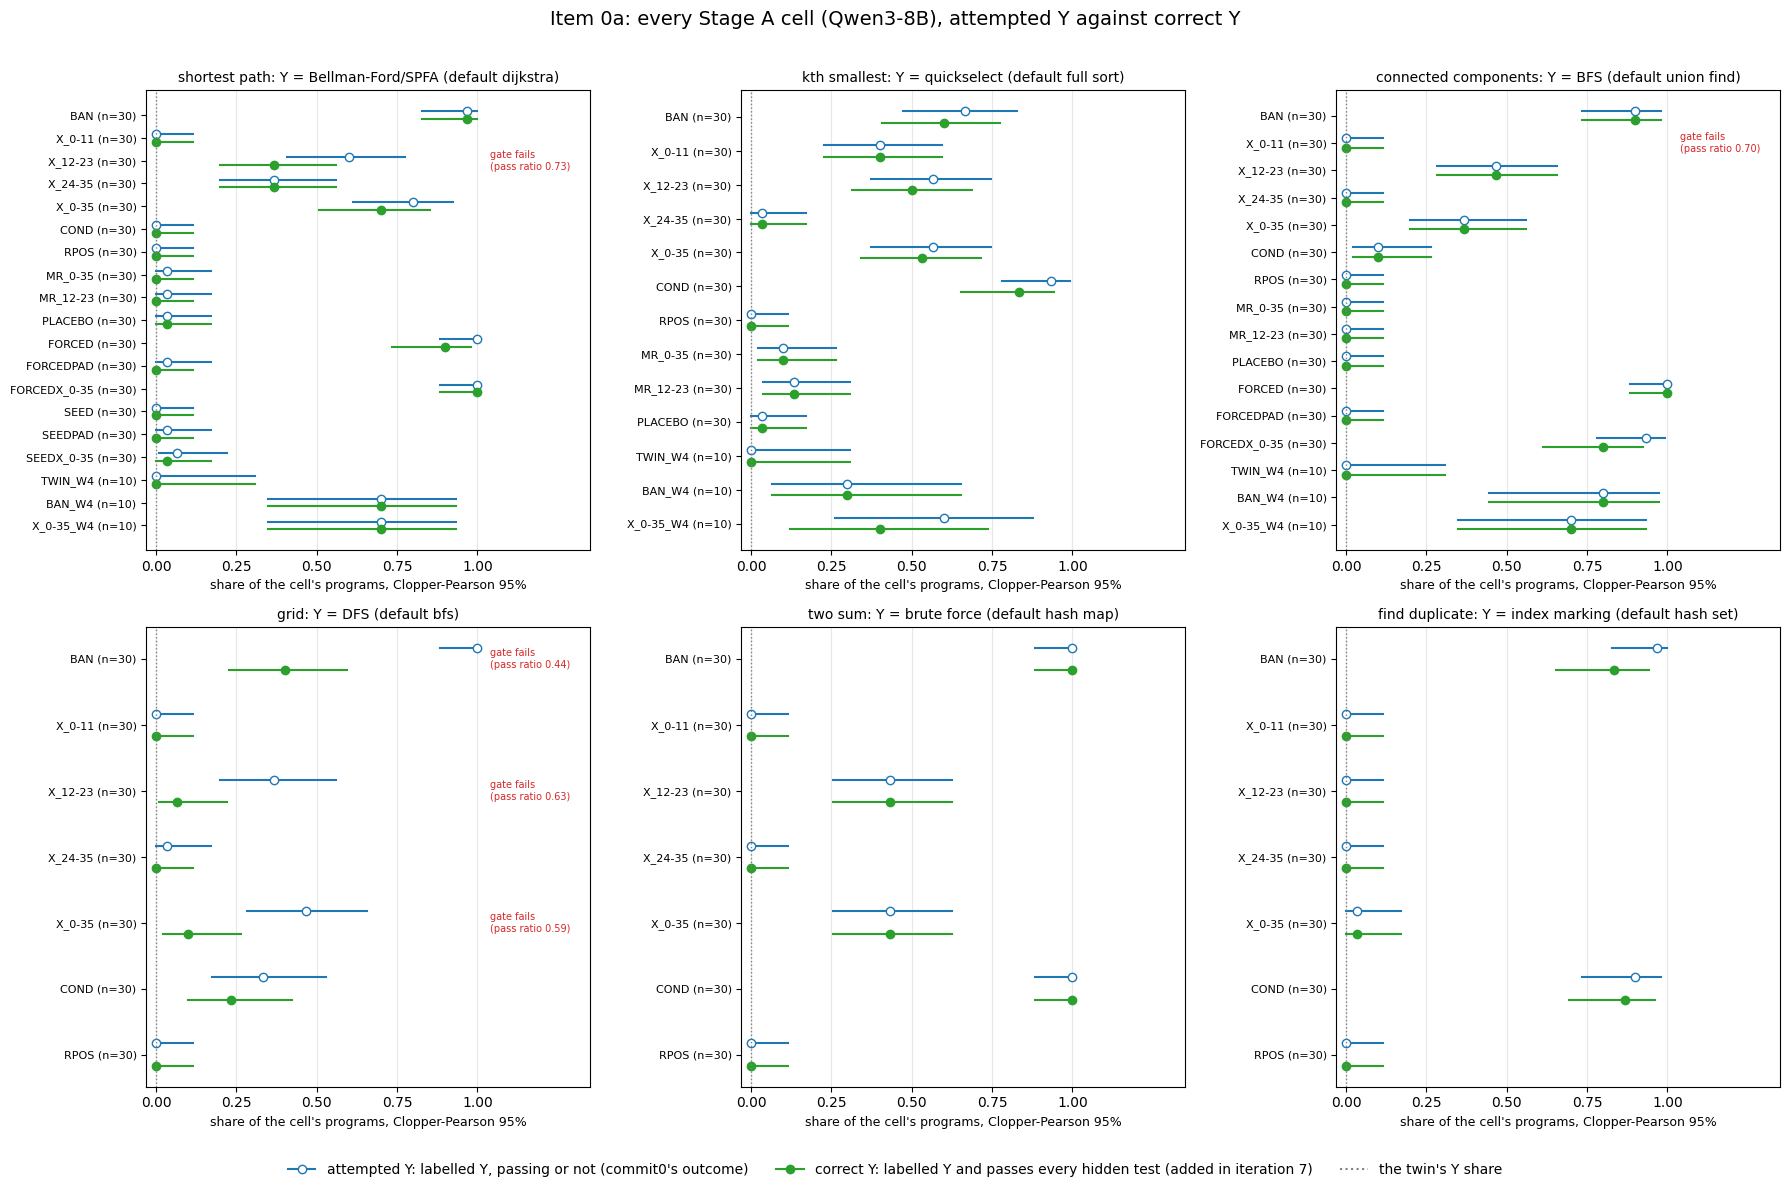

In [26]:
order = ["BAN", "X_0-11", "X_12-23", "X_24-35", "X_0-35", "COND", "RPOS", "MR_0-35", "MR_12-23", "PLACEBO",
         "FORCED", "FORCEDPAD", "FORCEDX_0-35", "SEED", "SEEDPAD", "SEEDX_0-35", "TWIN_W4", "BAN_W4", "X_0-35_W4"]
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, t in zip(axes.flat, ("T2", "T03", "T10", "T1", "T05", "T06")):
    tw = A["cells"][f"{t}|TWIN"]
    cs = [A["cells"][f"{t}|{k}"] for k in order if f"{t}|{k}" in A["cells"]]
    for i, c in enumerate(cs):
        y = len(cs) - 1 - i
        ax.plot(c["Y_ci95_cp"], [y + 0.17] * 2, color="tab:blue", lw=1.5)
        ax.plot(c["Y_share"], y + 0.17, "o", color="tab:blue", mfc="white", ms=6)
        ax.plot(c["correct_Y_ci95_cp"], [y - 0.17] * 2, color="tab:green", lw=1.5)
        ax.plot(c["correct_Y_share"], y - 0.17, "o", color="tab:green", ms=6)
        if c.get("gate_ok") is False:
            pr = "n/a" if c["pass_ratio"] is None else f"{c['pass_ratio']:.2f}"
            ax.text(1.04, y, f"gate fails\n(pass ratio {pr})", color="tab:red", va="center", fontsize=7)
    ax.axvline(tw["Y_share"], color="grey", ls=":", lw=1)
    ax.set_yticks(range(len(cs)), [f"{c['cell']} (n={c['n']})" for c in reversed(cs)], fontsize=8)
    ax.set_xlim(-0.03, 1.35)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.grid(axis="x", alpha=0.3)
    ax.set_title(f"{TASK_NAME[t]}: Y = {Y_NAME[tw['Y']]} (default {tw['default'].replace('_', ' ')})", fontsize=10)
    ax.set_xlabel("share of the cell's programs, Clopper-Pearson 95%", fontsize=9)
handles = [plt.Line2D([], [], color="tab:blue", marker="o", mfc="white",
                      label="attempted Y: labelled Y, passing or not (commit0's outcome)"),
           plt.Line2D([], [], color="tab:green", marker="o",
                      label="correct Y: labelled Y and passes every hidden test (added in iteration 7)"),
           plt.Line2D([], [], color="grey", ls=":", label="the twin's Y share")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=10, frameon=False)
fig.suptitle("Item 0a: every Stage A cell (Qwen3-8B), attempted Y against correct Y", fontsize=14)
fig.tight_layout(rect=(0, 0.035, 1, 0.97))
plt.show()

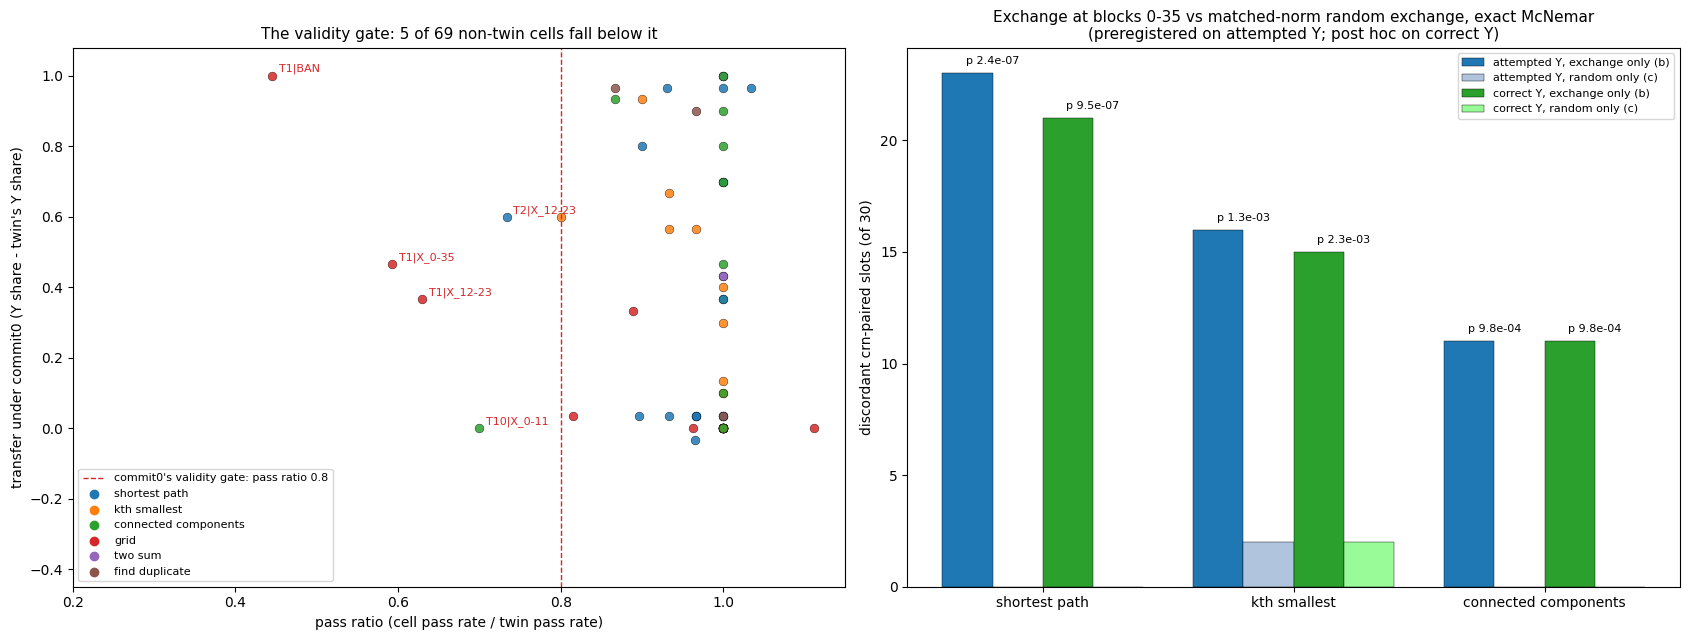

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5))
tcol = dict(zip(("T2", "T03", "T10", "T1", "T05", "T06"), plt.cm.tab10.colors))
for k, c in A["cells"].items():
    if c["cell"] == "TWIN" or c.get("pass_ratio") is None:
        continue
    ax1.scatter(c["pass_ratio"], c["transfer"], color=tcol[c["task"]], s=40, alpha=0.85, edgecolor="k", lw=0.3)
    if not c["gate_ok"]:
        ax1.annotate(k, (c["pass_ratio"], c["transfer"]), xytext=(5, 3), textcoords="offset points", fontsize=8,
                     color="tab:red")
ax1.axvline(0.8, color="tab:red", ls="--", lw=1, label="commit0's validity gate: pass ratio 0.8")
for t, colr in tcol.items():
    ax1.scatter([], [], color=colr, label=TASK_NAME[t])
ax1.set_xlim(0.2, 1.15)
ax1.set_ylim(-0.45, 1.08)
ax1.legend(fontsize=8, loc="lower left")
ax1.set_xlabel("pass ratio (cell pass rate / twin pass rate)")
ax1.set_ylabel("transfer under commit0 (Y share - twin's Y share)")
ax1.set_title(f"The validity gate: {len(fails)} of {sum(c['cell'] != 'TWIN' for c in A['cells'].values())} "
              "non-twin cells fall below it", fontsize=11)

tasks = list(A["mr_posthoc"])
x = np.arange(len(tasks))
bw = 0.2
for j, (key, lab, colr) in enumerate((("attempted_b", "attempted Y, exchange only (b)", "tab:blue"),
                                      ("attempted_c", "attempted Y, random only (c)", "lightsteelblue"),
                                      ("correct_b", "correct Y, exchange only (b)", "tab:green"),
                                      ("correct_c", "correct Y, random only (c)", "palegreen"))):
    ax2.bar(x + (j - 1.5) * bw, [A["mr_posthoc"][t][key] for t in tasks], bw, color=colr, edgecolor="k", lw=0.3,
            label=lab)
for i, t in enumerate(tasks):
    r = A["mr_posthoc"][t]
    ax2.text(i - bw, max(r["attempted_b"], r["attempted_c"]) + 0.4, f"p {r['attempted_p']:.1e}", ha="center", fontsize=8)
    ax2.text(i + bw, max(r["correct_b"], r["correct_c"]) + 0.4, f"p {r['correct_p']:.1e}", ha="center", fontsize=8)
ax2.set_xticks(x, [TASK_NAME[t] for t in tasks])
ax2.set_ylabel("discordant crn-paired slots (of 30)")
ax2.set_title("Exchange at blocks 0-35 vs matched-norm random exchange, exact McNemar\n"
              "(preregistered on attempted Y; post hoc on correct Y)", fontsize=11)
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 3. Item 0f: the top-five push in activation space, and item 0b: noise sites against the exchange

**The activation-space figure (0f)** has three panels. All of them use the coordinates stored in `top5_push.json`, from Qwen3-8B on the grid task.

**(a) The whole PCA plane** of the ten forced-prompt centroids. The states are the mean block outputs 12-23 over the task-specification positions, divided by the median block norm.
- Each star is the mean state when the prompt forces one path-search algorithm.
- The orange lines follow each prompt template from the twin through alpha 1, 2, 4 and 8 of the top-five push.
- The shaded band is the PC1 span of the centroids, and alpha 1 already leaves it.
- The legend gives each condition's pass rate and the algorithms its programs implement. Up to alpha 4 the pushed model still writes BFS while its pass rate falls to 0.03. At alpha 8 it writes programs that match no known algorithm ("other").

**(b) A zoom on the centroids.** It shows the path-search manifold itself, with the twin, the prompt ban of BFS (squares) and the prompt ban of the top five (diamonds).
- **The prompt bans stay inside the centroids' PC1 span** (-0.098 to +0.144).
  - The BFS ban sits at PC1 0.06 to 0.11, beside the BFS and Dijkstra centroids, while the model switches to DFS.
  - The top-five ban sits at PC1 -0.02 to 0.03, among the GBFS, BiBFS and IDA* centroids.
- **The activation push lands far outside that span**: PC1 -0.44 at alpha 1.

**(c) The geodesic MDS** (6 nearest neighbours) that the experiment computed over the same 38 points.

**The concordance figure (0b)** shows the NEW Table 254b as bars.
- On kth smallest, noise and the exchange both act most at blocks 12-23.
- On connected components they disagree: noise acts most at blocks 0-11, while the exchange transfers BFS at blocks 12-23.

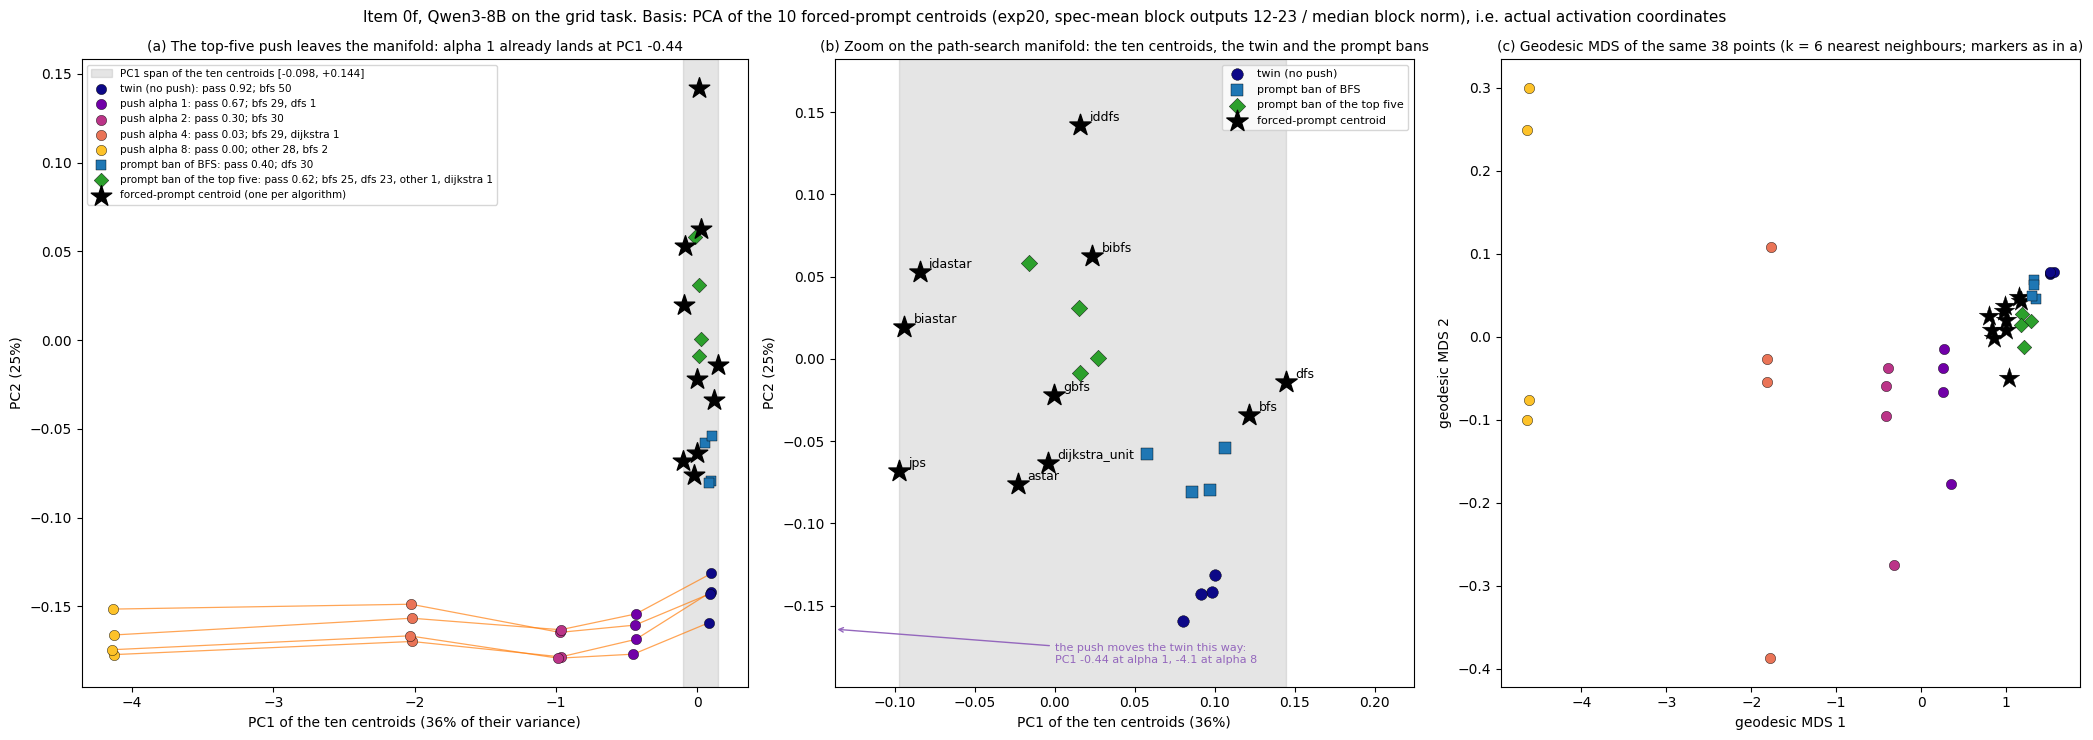

mean PC1 of the twin points +0.092; of the pushed points: push1 -0.441, push2 -0.972, push4 -2.026, push8 -4.132
pass rate by dose: alpha 1 0.67, alpha 2 0.30, alpha 4 0.03, alpha 8 0.00


In [28]:
if F is None:
    print("item 0f is not in ITEMS: add it to plot the top-five push geometry")
else:
    t5 = read_json(inp(EX, "results/top5_push.json"))
    G, cells5 = t5["geometry"], t5["cells"]
    Cxy, P = np.array(G["centroids_pc"]), G["points_pc"]
    tpls = sorted({k.split("__")[1] for k in P})
    doses = [("twin", "twin (no push)", "TWIN"), ("push1", "push alpha 1", "TOP5_a1"), ("push2", "push alpha 2", "TOP5_a2"),
             ("push4", "push alpha 4", "TOP5_a4"), ("push8", "push alpha 8", "TOP5_a8")]
    sty = {d: ("o", plt.cm.plasma(j / 4.6), 55) for j, (d, _, _) in enumerate(doses)}
    sty.update({"ban1": ("s", "tab:blue", 55), "top5ban": ("D", "tab:green", 55), "centroid": ("*", "black", 240)})
    comp = lambda cell: ", ".join(f"{a} {n}" for a, n in sorted(cells5[cell]["attempted_comp"].items(),
                                                                key=lambda kv: -kv[1]))
    lab = {d: f"{name}: pass {cells5[cell]['pass']:.2f}; {comp(cell)}" for d, name, cell in doses}
    lab.update({"ban1": f"prompt ban of BFS: pass {cells5['BAN']['pass']:.2f}; {comp('BAN')}",
                "top5ban": f"prompt ban of the top five: pass {cells5['TOP5BAN']['pass']:.2f}; {comp('TOP5BAN')}",
                "centroid": "forced-prompt centroid (one per algorithm)"})
    lo, hi = F["centroid_pc1_range"]
    e1, e2 = G["explained_by_pc1_pc2_of_centroids"]
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7.5), gridspec_kw={"width_ratios": [1.15, 1, 1]})
    # (a) the whole plane: every dose of the push, with the PC1 span of the centroids shaded
    ax1.axvspan(lo, hi, color="grey", alpha=0.2, label=f"PC1 span of the ten centroids [{lo:+.3f}, {hi:+.3f}]")
    for w_ in tpls:
        xy = np.array([P[f"{d}__{w_}"] for d, _, _ in doses])
        ax1.plot(xy[:, 0], xy[:, 1], color="tab:orange", lw=0.9, alpha=0.7, zorder=1)
    for d in [d for d, _, _ in doses] + ["ban1", "top5ban"]:
        xy = np.array([P[f"{d}__{w_}"] for w_ in tpls])
        mk, colr, sz = sty[d]
        ax1.scatter(xy[:, 0], xy[:, 1], marker=mk, color=colr, s=sz, edgecolor="k", lw=0.3, zorder=3, label=lab[d])
    mk, colr, sz = sty["centroid"]
    ax1.scatter(Cxy[:, 0], Cxy[:, 1], marker=mk, color=colr, s=sz, zorder=4, label=lab["centroid"])
    ax1.set_xlabel(f"PC1 of the ten centroids ({e1:.0%} of their variance)")
    ax1.set_ylabel(f"PC2 ({e2:.0%})")
    ax1.set_title("(a) The top-five push leaves the manifold: alpha 1 already lands at PC1 -0.44", fontsize=10)
    ax1.legend(fontsize=7.5, loc="upper left")
    # (b) zoom on the ten centroids, with the twin and the two prompt bans (the push points lie off this panel)
    near = np.vstack([Cxy] + [np.array([P[f"{d}__{w_}"] for w_ in tpls]) for d in ("twin", "ban1", "top5ban")])
    ax2.axvspan(lo, hi, color="grey", alpha=0.2)
    for d in ("twin", "ban1", "top5ban"):
        xy = np.array([P[f"{d}__{w_}"] for w_ in tpls])
        mk, colr, sz = sty[d]
        ax2.scatter(xy[:, 0], xy[:, 1], marker=mk, color=colr, s=sz + 15, edgecolor="k", lw=0.3, zorder=3,
                    label=lab[d].split(":")[0])
    ax2.scatter(Cxy[:, 0], Cxy[:, 1], marker="*", color="black", s=260, zorder=4, label="forced-prompt centroid")
    for name, (x0, y0) in zip(G["centroid_names"], Cxy):
        ax2.annotate(name, (x0, y0), xytext=(7, 3), textcoords="offset points", fontsize=9)
    pad = 0.04
    x_lo, y_lo = near[:, 0].min() - pad, near[:, 1].min() - pad
    ax2.set_xlim(x_lo, near[:, 0].max() + 2 * pad)
    ax2.set_ylim(y_lo, near[:, 1].max() + pad)
    ax2.annotate("the push moves the twin this way:\nPC1 -0.44 at alpha 1, -4.1 at alpha 8", xy=(x_lo, y_lo + 0.035),
                 xytext=(0.0, y_lo + 0.02), fontsize=8, color="tab:purple", va="center",
                 arrowprops=dict(arrowstyle="->", color="tab:purple"))
    ax2.set_xlabel(f"PC1 of the ten centroids ({e1:.0%})")
    ax2.set_ylabel(f"PC2 ({e2:.0%})")
    ax2.set_title("(b) Zoom on the path-search manifold: the ten centroids, the twin and the prompt bans", fontsize=10)
    ax2.legend(fontsize=8, loc="upper right")
    # (c) the experiment's own geodesic MDS of the same 38 points (markers and colours as in panel a)
    M = G["mds_geodesic_knn"]
    mxy = np.array(M["xy"])
    grp = [l.split("__")[0] if "__" in l else "centroid" for l in M["labels"]]
    for gname in dict.fromkeys(grp):
        idx = [i for i, gg in enumerate(grp) if gg == gname]
        mk, colr, sz = sty[gname]
        ax3.scatter(mxy[idx, 0], mxy[idx, 1], marker=mk, color=colr, s=sz, edgecolor="k", lw=0.3)
    ax3.set_xlabel("geodesic MDS 1")
    ax3.set_ylabel("geodesic MDS 2")
    ax3.set_title(f"(c) Geodesic MDS of the same 38 points (k = {M['k']} nearest neighbours; markers as in a)",
                  fontsize=10)
    fig.suptitle(f"Item 0f, Qwen3-8B on the grid task. Basis: {G['basis']}", fontsize=11)
    fig.tight_layout()
    plt.show()
    print(f"mean PC1 of the twin points {F['twin_pc1']:+.3f}; of the pushed points: "
          + ", ".join(f"{k} {v:+.3f}" for k, v in F["push_pc1"].items()))
    print("pass rate by dose: " + ", ".join(f"alpha {a} {p:.2f}" for a, p in F["pass"].items()))

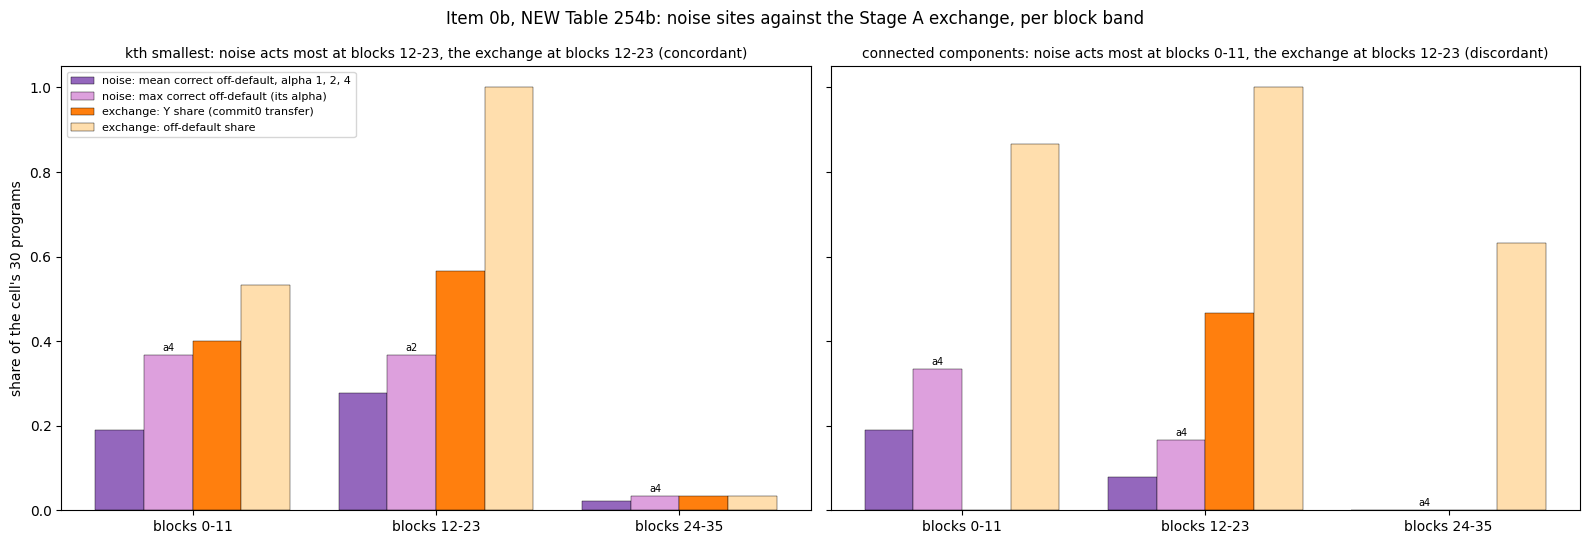

kth smallest          post-hoc condition-span beta -1.70, cluster bootstrap [-3.96, +0.42], profile [-6.82, +1.16]: the interval spans zero, the site is open
connected components  post-hoc condition-span beta -0.56, cluster bootstrap [-4.93, +2.91], profile [-6.15, +3.41]: the interval spans zero, the site is open
connected components: S4 coefficient +2.51 [1.39, 3.80]; paired flips 4:18 (p 0.004); off union find at blocks 0-11 0.87, at blocks 24-35 0.63
rule label: 'WITHDRAWN as FP8-specific: the site of the choice is open'


In [29]:
if B is None:
    print("item 0b is not in ITEMS: add it to plot Table 254b")
else:
    bands = ("0-11", "12-23", "24-35")
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
    for ax, t in zip(axes, ("T03", "T10")):
        cc = B["concordance"][t]
        x = np.arange(len(bands))
        for j, (key, lab_, colr) in enumerate((("noise_mean_by_band", "noise: mean correct off-default, alpha 1, 2, 4", "tab:purple"),
                                               ("noise_max_by_band", "noise: max correct off-default (its alpha)", "plum"),
                                               ("exchange_Y_transfer_by_band", "exchange: Y share (commit0 transfer)", "tab:orange"),
                                               ("exchange_off_default_by_band", "exchange: off-default share", "navajowhite"))):
            ax.bar(x + (j - 1.5) * 0.2, [cc[key][b] for b in bands], 0.2, color=colr, edgecolor="k", lw=0.3, label=lab_)
        for i, b in enumerate(bands):
            ax.text(x[i] - 0.1, cc["noise_max_by_band"][b] + 0.01, f"a{cc['noise_alpha_at_max'][b]}", ha="center",
                    fontsize=7)
        ax.set_xticks(x, [f"blocks {b}" for b in bands])
        ax.set_title(f"{TASK_NAME[t]}: noise acts most at blocks {cc['noise_band']}, the exchange at blocks "
                     f"{cc['exchange_band']} ({'concordant' if cc['concordant'] else 'discordant'})", fontsize=10)
    axes[0].set_ylabel("share of the cell's 30 programs")
    axes[0].legend(fontsize=8)
    fig.suptitle("Item 0b, NEW Table 254b: noise sites against the Stage A exchange, per block band", fontsize=12)
    fig.tight_layout()
    plt.show()
    for t in ("T03", "T10"):
        b_, cb, pr = B["posthoc_S2"][t]
        print(f"{TASK_NAME[t]:21} post-hoc condition-span beta {b_:+.2f}, cluster bootstrap [{cb[0]:+.2f}, {cb[1]:+.2f}], "
              f"profile [{pr[0]:+.2f}, {pr[1]:+.2f}]: the interval spans zero, the site is open")
    fl = B["flips_S0_vs_S4"]
    print(f"connected components: S4 coefficient {B['S4'][0]:+.2f} [{B['S4'][1][0]:.2f}, {B['S4'][1][1]:.2f}]; paired "
          f"flips {fl['S0_only']}:{fl['other_only']} (p {fl['p']:.3f}); off union find at blocks 0-11 "
          f"{B['depth_redundancy']['X_0-11_off_default']:.2f}, at blocks 24-35 {B['depth_redundancy']['X_24-35_off_default']:.2f}")
    print(f"rule label: {B['rule_label']!r}")

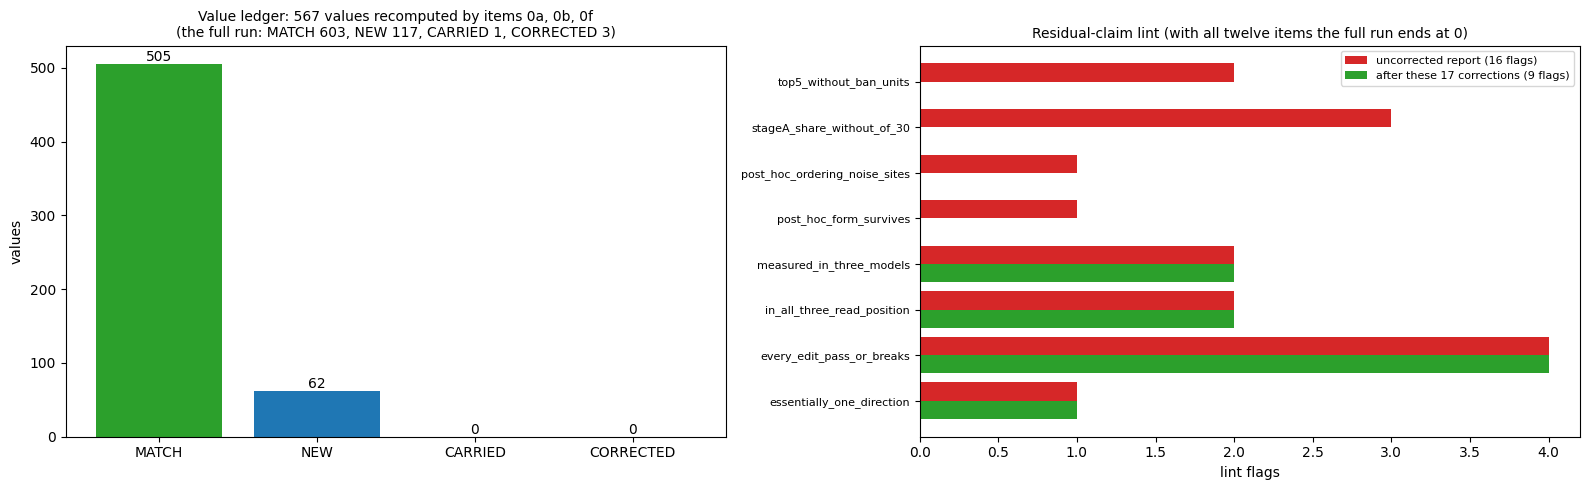

9 flags left after these corrections (line numbers in report_corrected.md); the full run clears each of them:
  line 5848  every_edit_pass_or_breaks (cleared by item 0c or 0d): ...tures move the fork, difference in means moves it more, and every fork edit breaks program...
  line 5848  every_edit_pass_or_breaks (cleared by item 0c or 0d): ...me norm to 46 and 49, and random latents to 21 (Table 262). Every edit at the fork lowered...
  line 6144  in_all_three_read_position (cleared by item 0d): ...ens later, and edits work only at the generated-token site. In all three the read position...
  line 6169  every_edit_pass_or_breaks (cleared by item 0c or 0d): ...hed norm, both move the plan equally at matched effect, and every edit toward the minority...
  line 6195  measured_in_three_models (cleared by item 0d): ...alves came out differently. Where the choice is held is now measured in three models: the ...
  line 6209  measured_in_three_models (cleared by item 0d): ...Where the choice is

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
order_s = ["MATCH", "NEW", "CARRIED", "CORRECTED"]
counts = [by_status.get(s, 0) for s in order_s]
bars = ax1.bar(order_s, counts, color=["tab:green", "tab:blue", "tab:gray", "tab:red"])
for b_, n_ in zip(bars, counts):
    ax1.text(b_.get_x() + b_.get_width() / 2, n_, str(n_), ha="center", va="bottom")
ax1.set_ylabel("values")
ax1.set_title(f"Value ledger: {len(all_vals)} values recomputed by items {', '.join(ITEMS)}\n"
              f"(the full run: {', '.join(f'{k} {v}' for k, v in ref['value_status_counts'].items())})", fontsize=10)
rules = sorted({h["rule"] for h in lint_before})
cnt_b, cnt_a = Counter(h["rule"] for h in lint_before), Counter(h["rule"] for h in lint_after)
yy = np.arange(len(rules))
ax2.barh(yy + 0.2, [cnt_b[r] for r in rules], 0.4, color="tab:red", label=f"uncorrected report ({len(lint_before)} flags)")
ax2.barh(yy - 0.2, [cnt_a[r] for r in rules], 0.4, color="tab:green",
         label=f"after these {len(corr)} corrections ({len(lint_after)} flags)")
ax2.set_yticks(yy, rules, fontsize=8)
ax2.set_xlabel("lint flags")
ax2.set_title("Residual-claim lint (with all twelve items the full run ends at 0)", fontsize=10)
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()
# which item's correction clears each rule's flags in the full run (from the published corrections.json)
cleared_by = {"stageA_share_without_of_30": "0a", "post_hoc_form_survives": "0b", "post_hoc_ordering_noise_sites": "0b",
              "top5_without_ban_units": "0f", "every_edit_pass_or_breaks": "0c or 0d", "in_all_three_read_position": "0d",
              "measured_in_three_models": "0d", "essentially_one_direction": "0d"}
print(f"{len(lint_after)} flags left after these corrections (line numbers in report_corrected.md); "
      "the full run clears each of them:")
for h in lint_after:
    print(f"  line {h['line']}  {h['rule']} (cleared by item {cleared_by[h['rule']]}): ...{h['snippet'][:90]}...")

## Scaling back to the full run

At `ITEMS = ["0a", "0b", "0f"]` the demo runs at its largest scale, with the original parameters. That covers every item whose inputs it bundles, all 75 Stage A cells and all 2,190 Stage A rows.

The complete evaluation runs from the artifact folder, the one that holds `eval.py`, `src/` and the 69 vendored inputs:

```bash
bash restore.sh                     # .venv with the exact pinned versions of pyproject.toml
uv run eval.py --stages offline     # all twelve items; reuses the cached judge and web results (about 20 s)
python3 -I audit/rederive.py        # the independent stdlib audit with placebos (520 checks)
python3 -I audit/headline_check.py  # the headline re-derivation with placebos (35 checks)
uv run eval.py --stages all         # optional: re-runs the paid judges and the live web pass (about USD 0.08)
```

The other items each need their own experiment:

| Items | Input |
|-|-|
| 0c, 0d | Gemma, `art_zNyBP6zieI5u` |
| 0g, 0i | the engine control, `art_lpQalcAXMGr1` |
| 0h | NLA, `art_dbUtqBjT0tPf` |
| 0j | the iteration-6 Step 0, `art_aRTQM6CQ0Dre` |
| 0k | the positioning audit and the web |

`make_mini_demo_data.py`, next to this notebook, rebuilds `mini_demo_data.json` from the artifact folder.